In [1]:
import pandas as pd 
import numpy as np
import nibabel as nib
import ants
import torch
import matplotlib.pyplot as plt
import seaborn as sns
import plotly
plotly.tools.set_credentials_file(username='Qqin', api_key='GFe6E0uLlZmHtoobrxiv')
import plotly.plotly as py
import plotly.graph_objs as go
from skimage import exposure
from skimage.restoration import denoise_wavelet
from matplotlib import gridspec
from matplotlib.backends.backend_pdf import PdfPages

sns.set("paper", font_scale=1.8)
sns.set_style("ticks", {"xtick.major.size": 0,
                        "ytick.major.size": 0,
                        'font.family': ['sans-serif']})
# plt.rc('text', usetex=False)
# plt.rc('font', family='serif')
%matplotlib inline

In [2]:
#bids = pd.read_table('results/bids_ready_datasets_annotation.xls')
#bids = bids.loc[(bids.age <= 8) & (bids.tesla != 'None'), :]

bids = pd.read_table('results/bids_delineated_updated.xls')
bids.loc[bids.tesla==3, 'tesla'] = bids.loc[bids.tesla==3, 'tesla'].astype(np.int32)

In [4]:
ID_counts = bids.ID.value_counts()

In [5]:
ID_counts = ID_counts.index[ID_counts>=2]

In [6]:
ID_counts

Int64Index([10262289, 10005576,    64780, 10841988, 10670047, 10839384,
            10796469, 10831701, 10825425,    62477, 10819181,    57284,
            10827206, 10836198, 10815438, 10005083, 10171679, 10804623,
            10292491, 10825839,    63265, 10826419, 10835526, 10823493,
            10832388, 10093806,    48517, 10840884,    44580, 10006509],
           dtype='int64')

In [7]:
bids.loc[bids.ID.isin([10002254]), :]

,ID,age,machine,platform,tesla,t1,t1s,t2f,t2,dwi,...,Cognitive_12m,Fine Motor_12m,Gross Motor_12m,Receptive Communication_12m,Expressive Communication_12m,Cognitive_18m,Fine Motor_18m,Gross Motor_18m,Receptive Communication_18m,Expressive Communication_18m
2016,10002254,3.0,SIEMENS,Avanto,1.5,../../../data/Shanghai/cont/source/sub-PA382/a...,../../../data/Shanghai/cont/source/sub-PA382/a...,../../../data/Shanghai/cont/source/sub-PA382/a...,../../../data/Shanghai/cont/source/sub-PA382/a...,../../../data/Shanghai/cont/source/sub-PA382/d...,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [8]:
bids.loc[bids.ID.isin(ID_counts), :].sort_values('ID').to_csv('check_images.csv')

## no need to remove redundancy by image IDs

In [9]:
#bids.drop_duplicates('ID', inplace=True)
bids.drop('ID', axis=1, inplace=True)
bids.to_csv('results/bids_head1.csv')

In [147]:
bids.shape

(1596, 38)

In [11]:
machine_platform = bids.apply(lambda x: "%s-%s-%.1fT" % (x[1], x[2], round(float(x[3]), 2)), axis=1)
print(machine_platform.value_counts())
print('-'*100)
print(bids.shape)
print(bids.columns)
bids.loc[:, 'merge_machine_info'] = machine_platform

SIEMENS-Avanto-1.5T                        856
GE MEDICAL SYSTEMS-DISCOVERY MR750-3.0T    538
SIEMENS-Skyra-3.0T                         202
dtype: int64
----------------------------------------------------------------------------------------------------
(1596, 37)
Index(['age', 'machine', 'platform', 'tesla', 't1', 't1s', 't2f', 't2', 'dwi',
       'adc', 'gender', 'Cyst', 'Leukomalacia', 'Hemorrhage',
       'Myelin_or_Develop', 'Expansion', 'Lesion', 'Control', 'pvl.ga',
       'pvl.birth', 'pvl.weig', 'pvl.head', 'pvl.label', 'pvl.length',
       'chen_label', 'qin_label', 'Leukomalacia.manual', 'Cognitive_12m',
       'Fine Motor_12m', 'Gross Motor_12m', 'Receptive Communication_12m',
       'Expressive Communication_12m', 'Cognitive_18m', 'Fine Motor_18m',
       'Gross Motor_18m', 'Receptive Communication_18m',
       'Expressive Communication_18m'],
      dtype='object')


In [12]:
print(bids.age.mean(), bids.age.std())

2.83252774794128 2.2551801085894563


In [13]:
pd.crosstab(bids.merge_machine_info, bids.Leukomalacia)

Leukomalacia,0,1
merge_machine_info,,
GE MEDICAL SYSTEMS-DISCOVERY MR750-3.0T,486,52
SIEMENS-Avanto-1.5T,571,285
SIEMENS-Skyra-3.0T,189,13


In [14]:
pd.crosstab(bids.merge_machine_info, bids.Hemorrhage)
pd.crosstab(bids.Leukomalacia, bids.Hemorrhage)

Hemorrhage,0,1
Leukomalacia,,
0,925,321
1,218,132


<Figure size 1296x576 with 0 Axes>

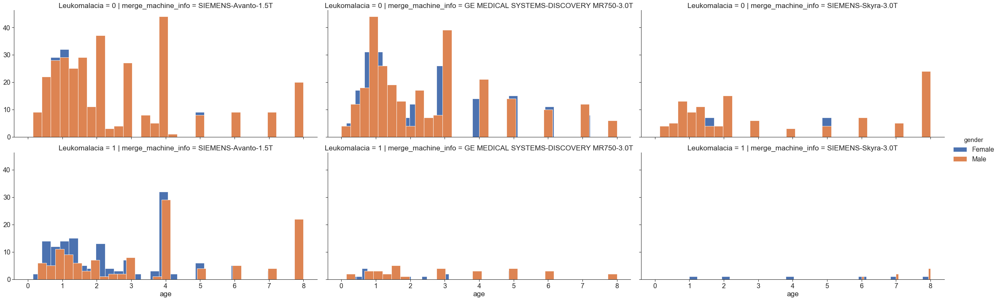

In [15]:
## https://zhuanlan.zhihu.com/p/27816821
## http://seaborn.pydata.org/generated/seaborn.FacetGrid.html
plt.figure(figsize=(18, 8))
g = sns.FacetGrid(bids, col="merge_machine_info", 
                  row="Leukomalacia", hue="gender",
                  height=5, aspect=2.1)
(g.map(plt.hist, "age", bins=30)).add_legend()
plt.savefig("results/Fig1_1.pdf")

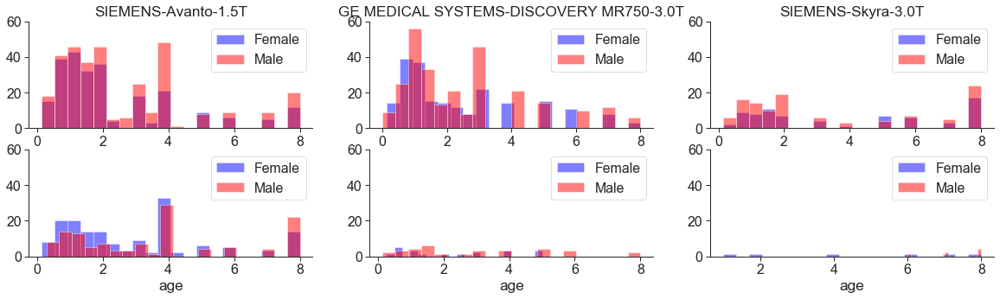

In [16]:
fig = plt.figure(figsize=(20, 5))
n = 0
for row in [0, 1]:
    for index, platform in enumerate(bids.merge_machine_info.unique()):
        n += 1
        plt.subplot(2, 3, n)
        for color, gender in enumerate(bids.gender.unique()):
            sns.distplot(bids.age[(bids.gender==gender) & 
                                  (bids.merge_machine_info==platform) &
                                  (bids.Leukomalacia==row)], 
                         bins=20, kde=False, 
                         color=['blue', 'red'][color], 
                         hist_kws={"alpha":0.5}, label=gender)
            plt.ylim([0, 60])
            if row == 0:
                plt.title(platform)
        plt.legend()
        sns.despine()
        
plt.savefig('results/Fig1_1.pdf')

# Case study of PVL

We shall select different PVL patients with various levels of lesions. We select one typical case with 4 symptoms: Expansion, Lesion, Leukomalacia, Hemorrhage. 

In [17]:
case1 = bids.loc[(bids.Expansion==1) & (bids.Lesion == 1) & (bids.Leukomalacia == 1) &
                 (bids.Hemorrhage==1) & (bids.Cyst==0) & (bids.loc[:, "Myelin_or_Develop"]==0), :]

In [18]:
def enhan(in_file, clip_limit=0.010):
    import numpy as np
    import nibabel as nb
    import os.path as op
    from skimage import exposure, img_as_int
    from nipype.utils import NUMPY_MMAP
    #im = nb.load(in_file, mmap=NUMPY_MMAP)
    #imdata = im.get_data()    
    im = ants.image_read(in_file)
    brain_mask = ants.get_mask(im)
    im = im.crop_image(brain_mask, label=1)
    im = im.denoise_image()
    imdata = im.numpy()
    imshape = im.shape

    immin = imdata.min()
    imdata = (imdata - immin).astype(np.uint16)

    adapted = exposure.equalize_adapthist(
        denoise_wavelet(imdata.reshape(imshape[0], -1)), clip_limit=clip_limit)
    return brain_mask, adapted.reshape(imshape)

## Add skull stripping with BET

In [66]:
#t2_file = case1.iloc[0, ].loc['t2']
t2_file = bids.loc[101, ].loc['t2']
t2_prefix = t2_file.replace('.nii.gz', '_processed')

!bet $t2_file $t2_prefix -m -R -f 0.4

## Registration to template from Imperial London College

In [68]:
image_modality_dict_case = {}
image_modality_dict_case['t2'] = ants.image_read(t2_file)
image_modality_dict_case['t2'] = ants.resample_image(image_modality_dict_case['t2'], (1,1,1), use_voxels=False)

image_modality_dict_case['mask'] = ants.image_read(f'{t2_prefix}_mask.nii.gz')
image_modality_dict_case['mask'] = ants.resample_image(image_modality_dict_case['mask'], (1,1,1), use_voxels=False)

for modality in ['t1', 't1s', 't2f', 'adc']:
    image_modality_dict_case[modality] = ants.image_read(case1.iloc[0, :].loc[modality])
    image_modality_dict_case[modality] = ants.registration(image_modality_dict_case['t2'], 
                                                      image_modality_dict_case[modality], 
                                                      type_of_transform='Rigid')
    image_modality_dict_case[modality] = image_modality_dict_case[modality]['warpedmovout']

In [69]:
for modality in ['t2','t1', 't1s', 't2f', 'adc', 'mask']: 
    image_modality_dict_case[modality] = image_modality_dict_case[modality] * image_modality_dict_case['mask']
    image_modality_dict_case[modality] = image_modality_dict_case[modality].crop_image(image_modality_dict_case['mask'])

In [70]:
def enhan_ants_image(ants_image, mask, clip_limit=0.015):
    import numpy as np
    from skimage import exposure, img_as_int  
    im = ants_image.denoise_image()
    imdata = im.numpy()
    imshape = im.shape

    immin = imdata.min()
    imdata = (imdata - immin).astype(np.uint16)

    adapted = exposure.equalize_adapthist(
        denoise_wavelet(imdata.reshape(imshape[0], -1)), clip_limit=clip_limit)
    
    adapted_image = adapted.reshape(imshape)
    return ants.make_image(mask.shape, voxval=adapted_image, 
                           spacing=(1,1,1), 
                           direction=ants.get_direction(mask), 
                           origin=ants.get_origin(mask))

/home/qinqian/.local/lib/python3.6/site-packages/pywt/_multilevel.py:408: FutureWarning:

Using a non-tuple sequence for multidimensional indexing is deprecated; use `arr[tuple(seq)]` instead of `arr[seq]`. In the future this will be interpreted as an array index, `arr[np.array(seq)]`, which will result either in an error or a different result.

/home/qinqian/.local/lib/python3.6/site-packages/skimage/util/dtype.py:135: UserWarning:

Possible precision loss when converting from float64 to uint16



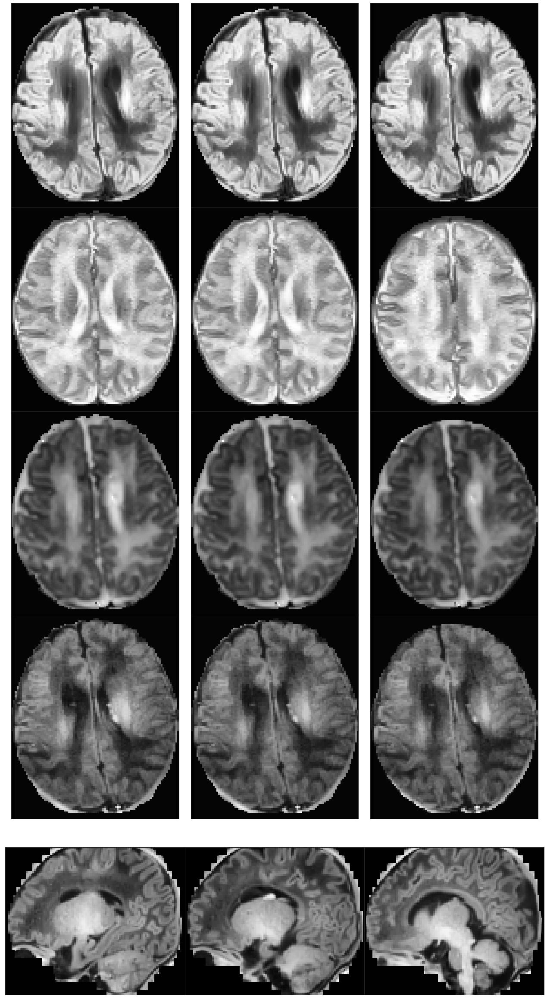

In [71]:
ncol = 3
nrow = 5
plt.figure(figsize=((nrow-2.2)*8, (ncol)*14.5))
gs = gridspec.GridSpec(nrow, ncol, wspace=0, hspace=0)
for row_index, i in enumerate(['t2f', 't2', 'adc', 't1', 't1s']):
    image_enhan = enhan_ants_image(image_modality_dict_case[i], image_modality_dict_case['mask']) 
#     if i == 't1s':
#         fig = image_enhan.plot(axis=0, slices=(60, 61, 62), ncol=3, figsize=8, filename='results/FigureS1_%s.pdf' % i)  
#     else:
#         fig = image_enhan.plot(axis=2, slices=(60, 61, 62), ncol=3, figsize=8, filename='results/FigureS1_%s.pdf' % i)
    if i != 't1s':
        slices = [60, 61, 62]
    else:
        slices = [32, 36, 40]        
    for col_index, sl in enumerate(slices):
        ax = plt.subplot(gs[row_index, col_index])
        ax.set_aspect('equal')
        if i != 't1s':
            ax.imshow(np.rot90(image_enhan[:, :, sl][::-1, :]), interpolation='nearest', cmap=plt.cm.gray) 
        else:
            ax.imshow(np.rot90(image_enhan[sl, :, :][::-1, :]), interpolation='nearest', cmap=plt.cm.gray)             
        ax.axis('image')
        ax.set_xticks([])
        ax.set_yticks([])
plt.savefig('results/FigureS1.pdf')

[[1 2 3]
 [4 5 6]]


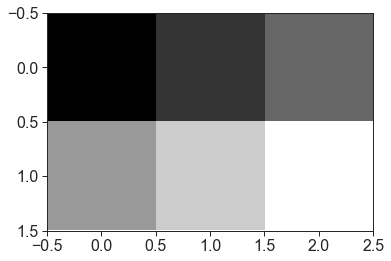

In [72]:
test_imshow = np.array([[1,2,3],[4,5,6]])
print(test_imshow)
plt.imshow(test_imshow, interpolation='nearest', cmap=plt.cm.gray)

## Public template does not work well

In [73]:
template_imperial = ants.image_read('../../../../data/Atlas/Regionalgrowth_and_atlas_Consistent_High_definition_Spatio-tempora/NeonatalAtlas2/template_T2_17.nii.gz')
print(template_imperial.shape)

(117, 159, 126)


In [74]:
ants.get_spacing(template_imperial)

(0.859375, 0.859375, 0.859375)

In [75]:
template_imperial = template_imperial.resample_image((1,1,1), use_voxels=False)

In [76]:
template_imperial = template_imperial.crop_image(template_imperial.get_mask())

In [77]:
print(template_imperial.shape)

(90, 122, 94)


## Build our template 

In [79]:
bids.loc[bids.age >= 8, 'merge_machine_info'].value_counts()

SIEMENS-Avanto-1.5T                        67
SIEMENS-Skyra-3.0T                         45
GE MEDICAL SYSTEMS-DISCOVERY MR750-3.0T    11
Name: merge_machine_info, dtype: int64

In [80]:
!mkdir -p results/template_candidates

In [81]:
import random

np.random.seed(999)
random.seed(999)

template_candidates = []
for platform in bids.merge_machine_info.unique():
    template_candidates += list(np.random.choice(bids.loc[(bids.age >= 8) & 
                                                          (bids.merge_machine_info == platform), :].index, 3, 
                                                 replace=False))

In [82]:
template_candidates

[1982, 1910, 1195, 451, 424, 324, 2196, 2529, 2937]

In [29]:
bids.loc[635, ]

age                                                                   8
machine                                              GE MEDICAL SYSTEMS
platform                                                DISCOVERY MR750
tesla                                                                 3
t1                    ../../../new_sequence/source/sub-46/anat/sub-4...
t1s                   ../../../new_sequence/source/sub-46/anat/sub-4...
t2f                   ../../../new_sequence/source/sub-46/anat/sub-4...
t2                    ../../../new_sequence/source/sub-46/anat/sub-4...
dwi                   ../../../new_sequence/source/sub-46/dwi/sub-46...
adc                   ../../../new_sequence/source/sub-46/dwi/sub-46...
gender                                                             Male
Cyst                                                                  0
Leukomalacia                                                          0
Hemorrhage                                                      

In [83]:
template_candidates.append(556)

In [84]:
image_modality_dict = {}

In [85]:
#for candidate in template_candidates:
image_modality_dict = {}
for candidate in [635, 556, 101]:

    t2_file = bids.loc[candidate, ].loc['t2']
    t2_prefix = t2_file.replace('.nii.gz', '_processed')
    !bet $t2_file $t2_prefix -m -R -f 0.4  

    image_modality_dict[candidate] = {}
    image_modality_dict[candidate]['t2'] = ants.image_read(t2_file)
    image_modality_dict[candidate]['t2'] = ants.resample_image(image_modality_dict[candidate]['t2'], (1,1,1), use_voxels=False)
    image_modality_dict[candidate]['mask'] = ants.image_read(f'{t2_prefix}_mask.nii.gz') 
    image_modality_dict[candidate]['mask'] = ants.resample_image(image_modality_dict[candidate]['mask'], 
                                                                (1,1,1), use_voxels=False)
    for modality in ['t1', 't1s', 't2f', 'adc']:
        image_modality_dict[candidate][modality] = ants.image_read(bids.loc[candidate, ].loc[modality])
        image_modality_dict[candidate][modality] = ants.registration(image_modality_dict[candidate]['t2'], 
                                                                     image_modality_dict[candidate][modality], 
                                                                     type_of_transform='Rigid')
        image_modality_dict[candidate][modality] = image_modality_dict[candidate][modality]['warpedmovout']
    for modality in ['t2', 't1', 't1s', 't2f', 'adc', 'mask']:
        image_modality_dict[candidate][modality] = image_modality_dict[candidate][modality] * image_modality_dict[candidate]['mask']        
        image_modality_dict[candidate][modality] = image_modality_dict[candidate][modality].crop_image(image_modality_dict[candidate]['mask'])

In [86]:
image_modality_dict.keys()

dict_keys([635, 556, 101])

In [87]:
enhan_image_modality_dict = {}
#for candidate in template_candidates:
for candidate in [635, 556, 101]:
    enhan_image_modality_dict[candidate] = {}
    for i in ['t2', 't1', 't1s', 't2f', 'adc']: 
        enhan_image_modality_dict[candidate][i] = enhan_ants_image(image_modality_dict[candidate][i], 
                                                                   image_modality_dict[candidate]['mask'])

/home/qinqian/.local/lib/python3.6/site-packages/pywt/_multilevel.py:408: FutureWarning:

Using a non-tuple sequence for multidimensional indexing is deprecated; use `arr[tuple(seq)]` instead of `arr[seq]`. In the future this will be interpreted as an array index, `arr[np.array(seq)]`, which will result either in an error or a different result.

/home/qinqian/.local/lib/python3.6/site-packages/skimage/util/dtype.py:135: UserWarning:

Possible precision loss when converting from float64 to uint16



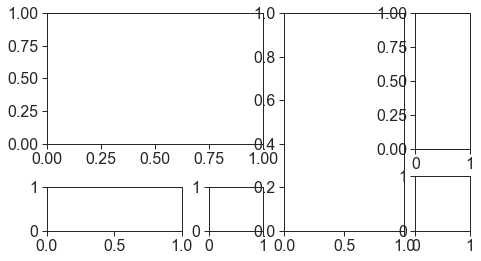

In [88]:
gs1 = gridspec.GridSpec(3, 3)
gs1.update(left=0.0, right=0.5, wspace=0.5, hspace=1)
ax1 = plt.subplot(gs1[:-1, :])
ax2 = plt.subplot(gs1[-1, :-1])
ax3 = plt.subplot(gs1[-1, -1])

gs2 = gridspec.GridSpec(3, 3)
gs2.update(left=0.55, right=0.98, hspace=0.5)
ax4 = plt.subplot(gs2[:, :-1])
ax5 = plt.subplot(gs2[:-1, -1])
ax6 = plt.subplot(gs2[-1, -1])

In [89]:
for patient in enhan_image_modality_dict.keys():
    for i in ['t1', 't1s', 't2', 'adc', 't2f']:
        ants.image_write(enhan_image_modality_dict[patient][i], 
                         f'results/template_candidates/{patient}_{i}_processed.nii.gz')

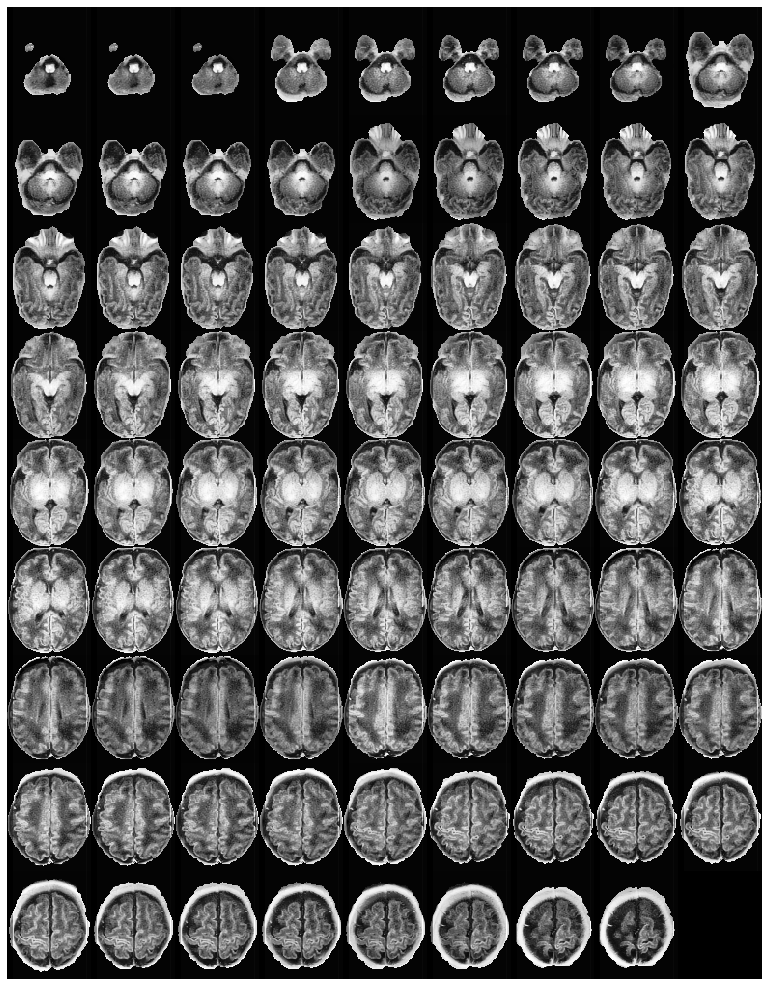

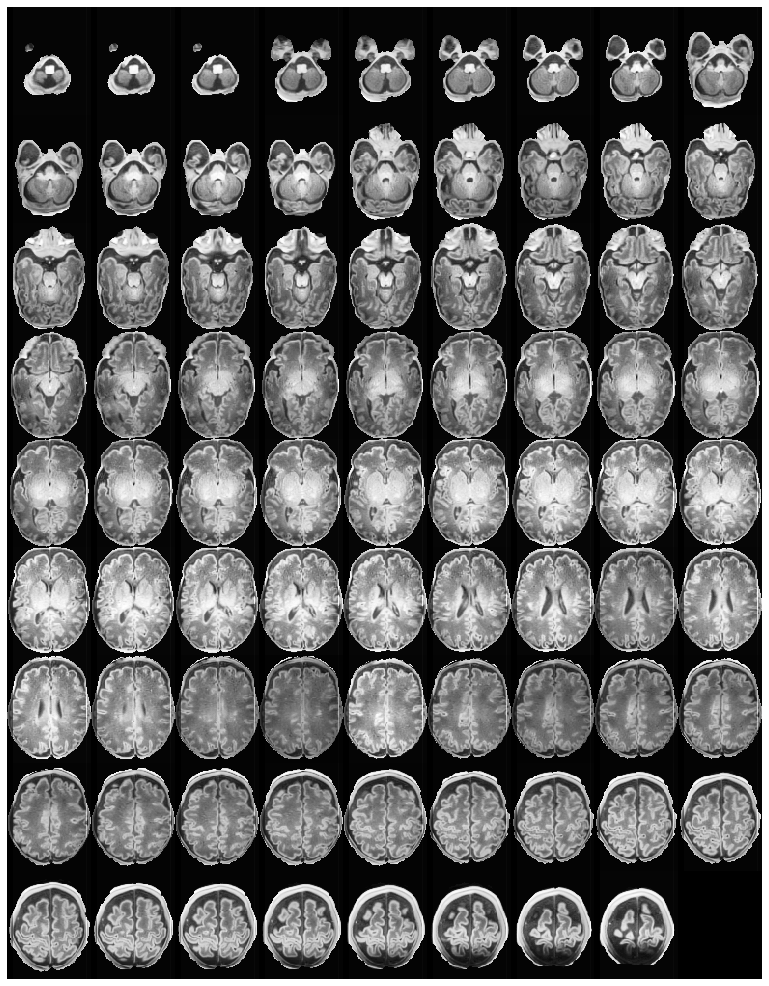

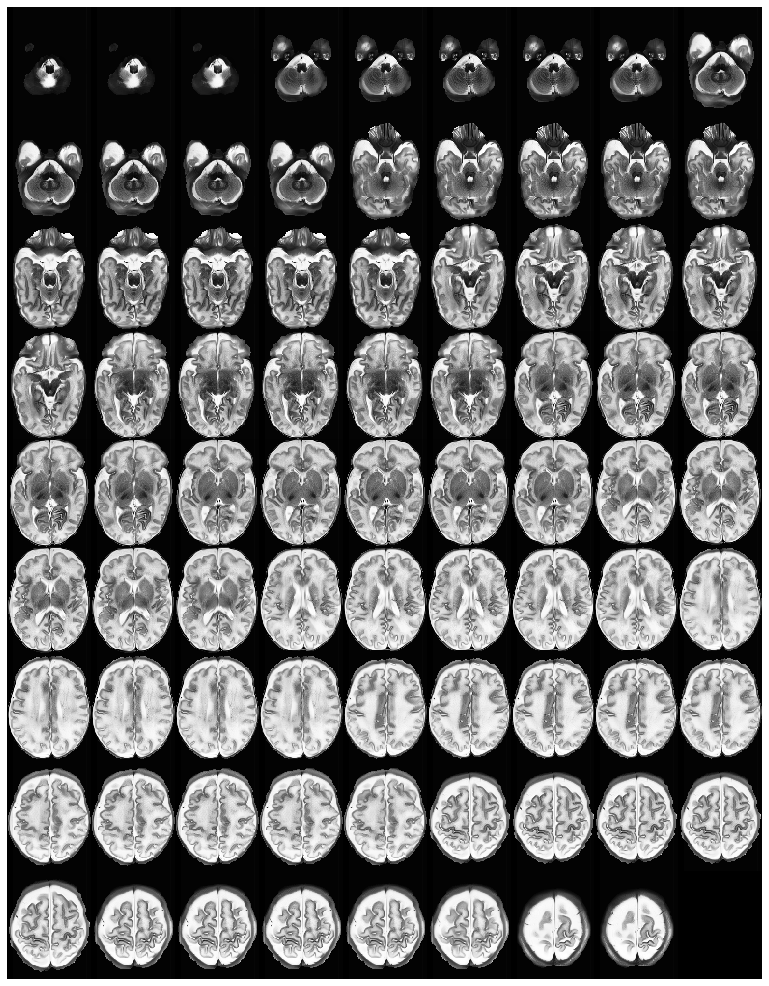

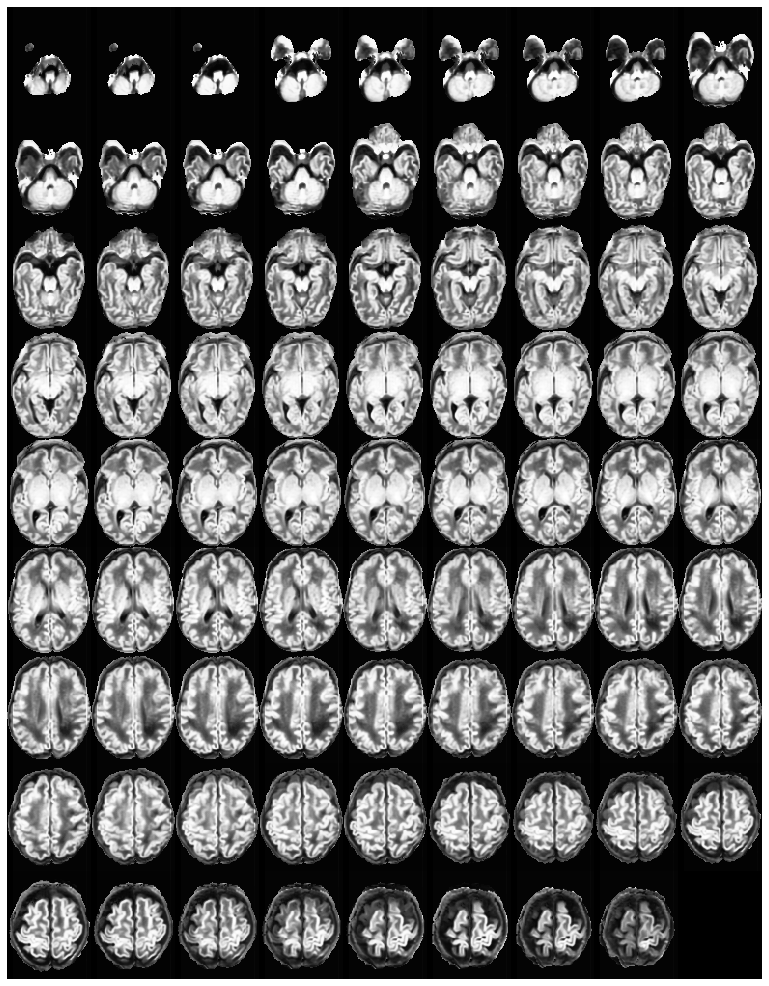

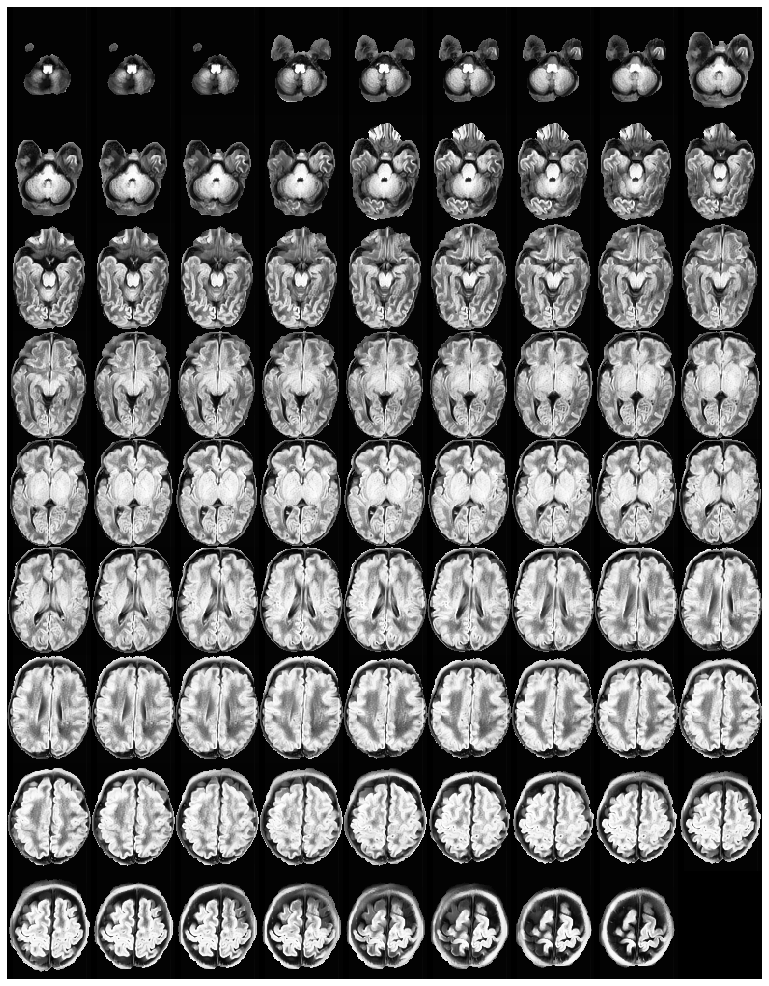

...

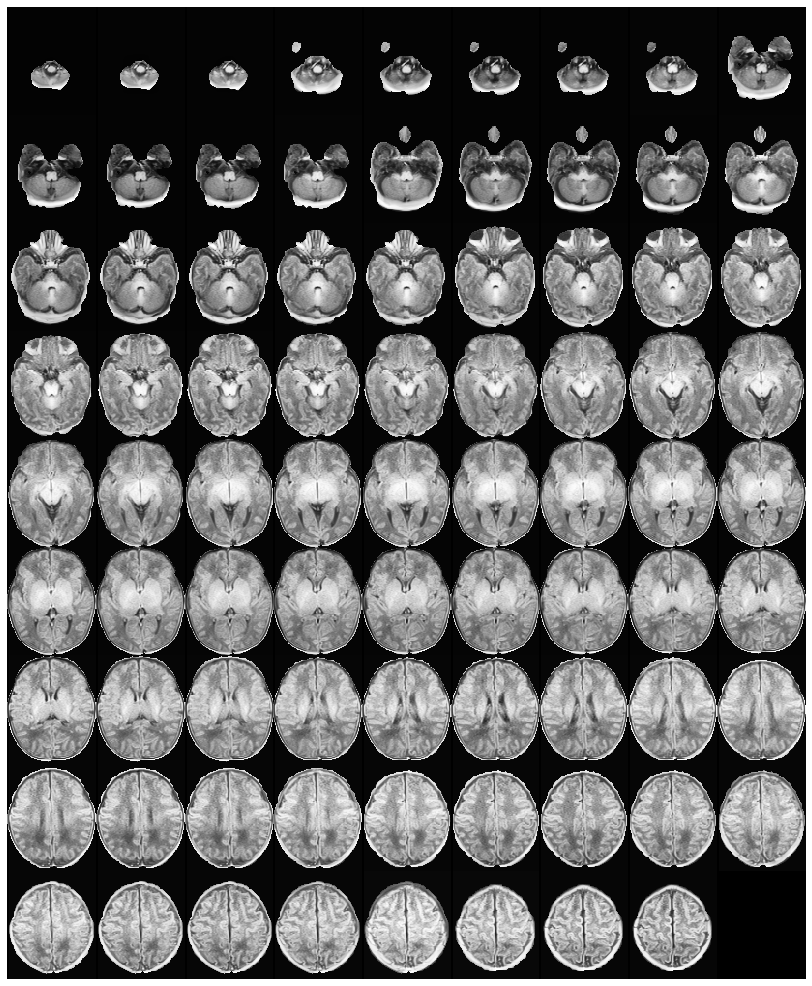

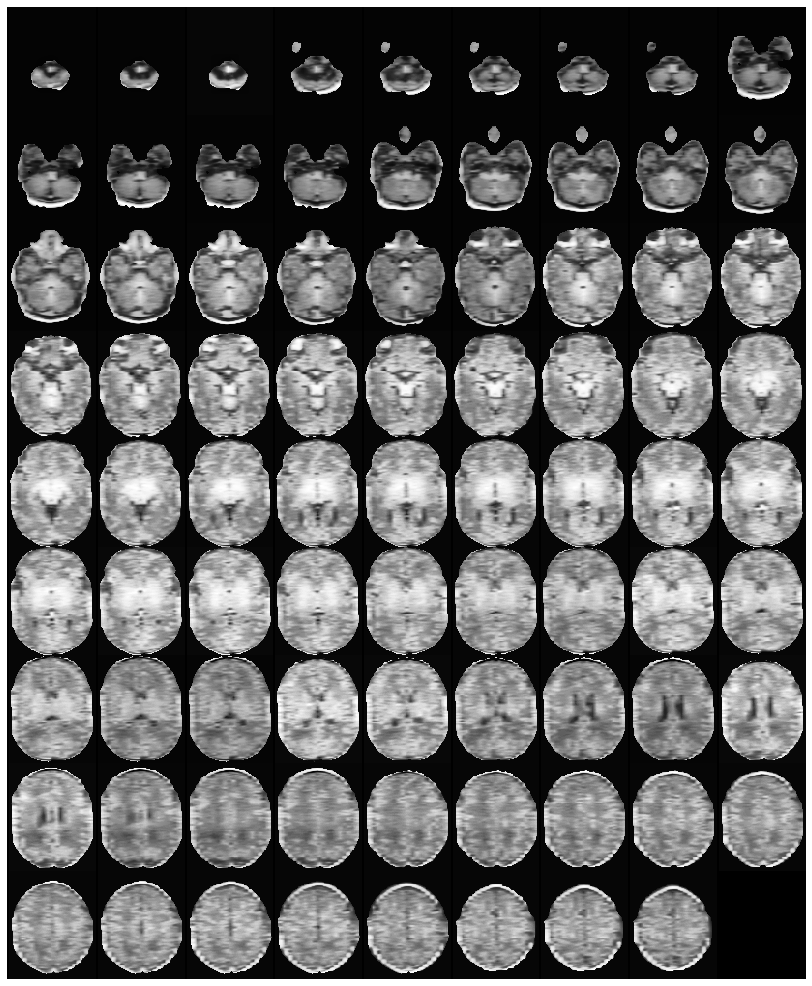

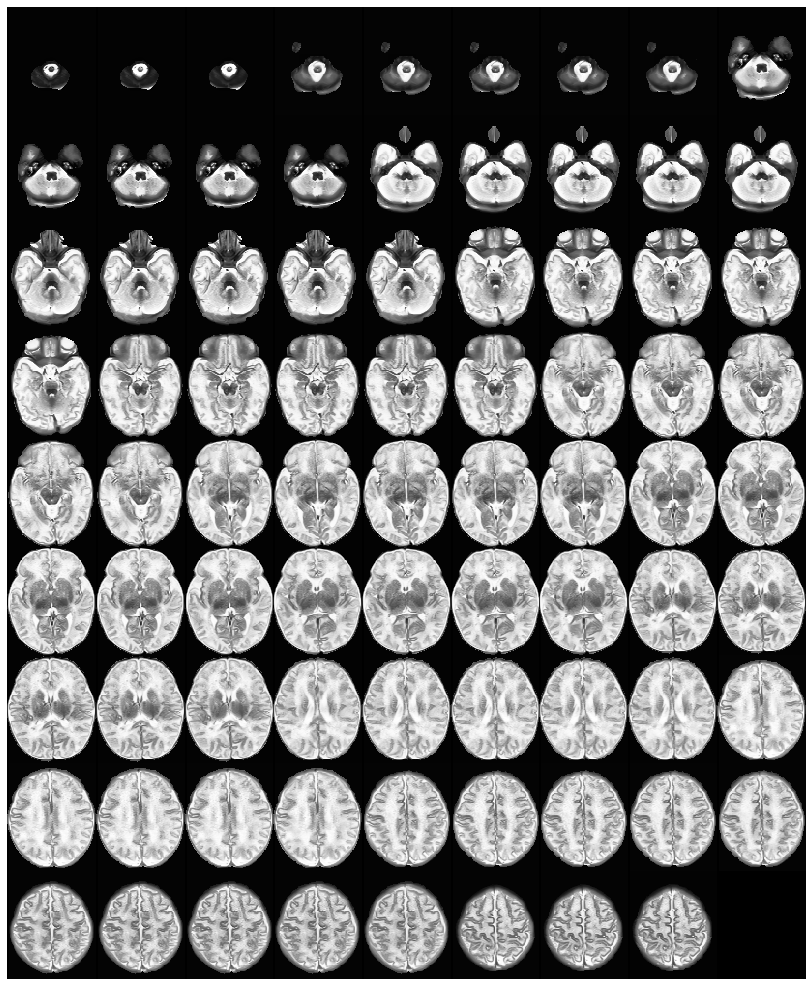

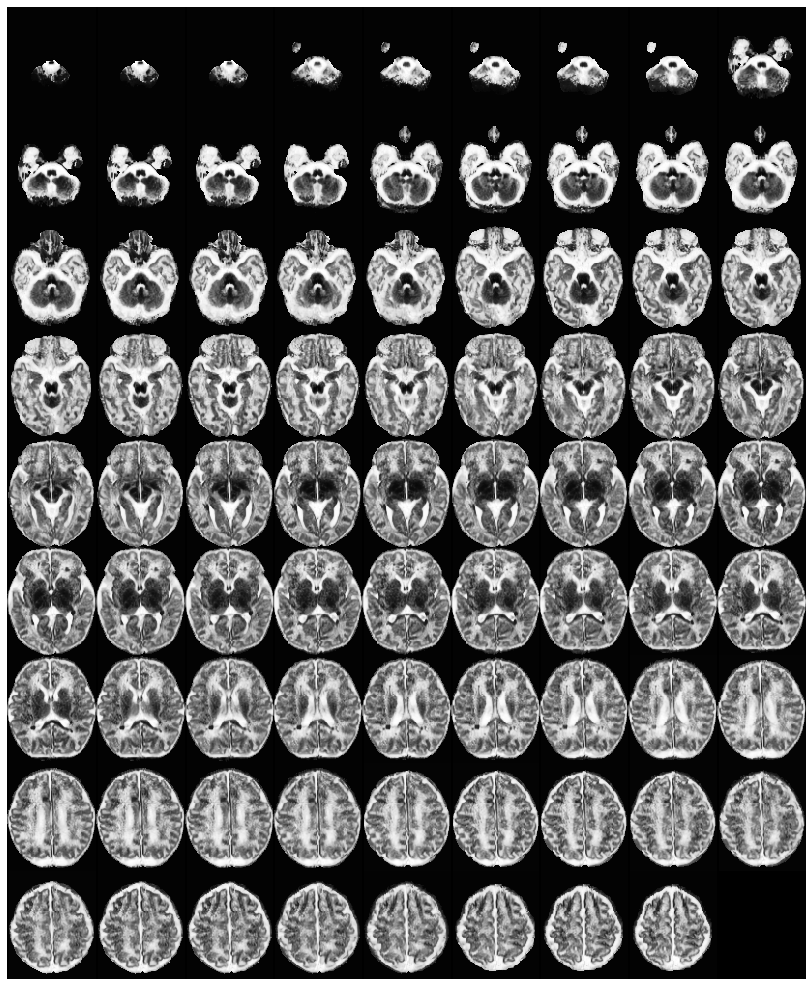

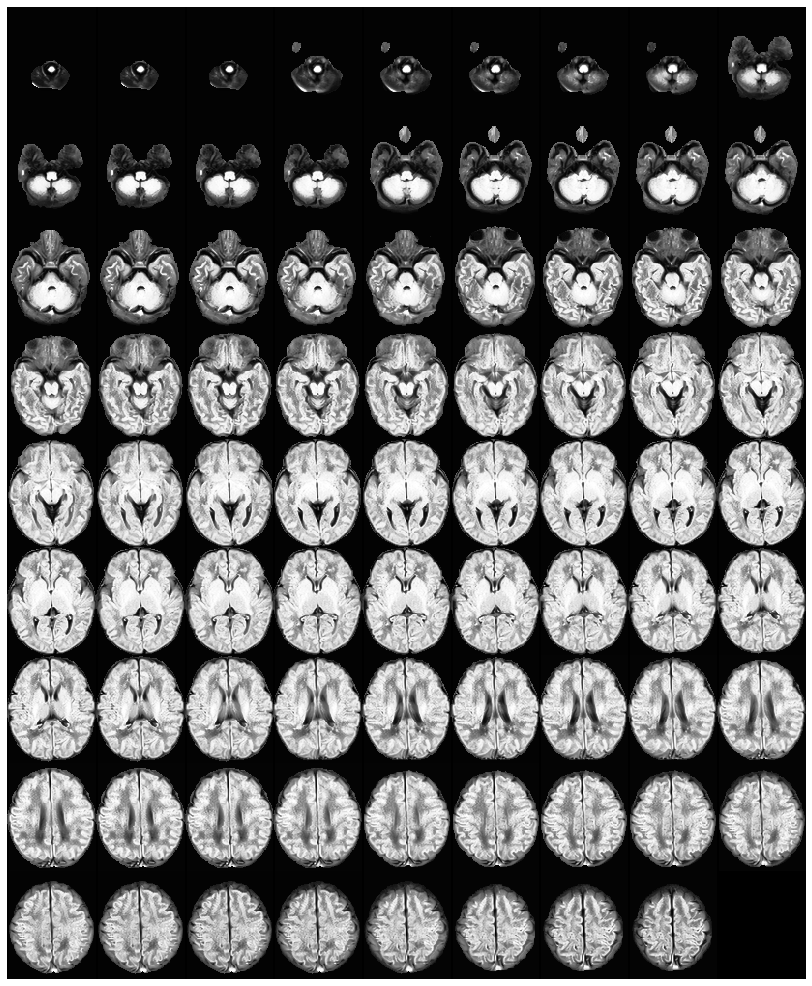

In [90]:
for i in enhan_image_modality_dict:
    for j in ['t1', 't1s', 't2', 'adc', 't2f']:
        enhan_image_modality_dict[i][j].plot(axis=2, slices=range(80))

In [124]:
enhan_image_modality_dict[i][j].shape

(92, 112, 92)

In [125]:
from collections import defaultdict
import os
template_df = defaultdict(list)
for patient in enhan_image_modality_dict.keys():    
     for i in ['t1', 't1s', 't2', 'adc', 't2f']:
         template_df[patient].append(os.path.abspath(f'results/template_candidates/{patient}_{i}_processed.nii.gz'))

In [455]:
template_df = pd.DataFrame(template_df, index=['t1', 't1s', 't2', 'adc', 't2f'])

In [456]:
template_df.transpose().to_csv('results/template_candidates/templateInput.csv', sep=',', index=None, header=None)

In [349]:
from ants.viz.render_surface_function import render_surface_function
render_surface_function(enhan_image_modality_dict[63]['t2'],
                        enhan_image_modality_dict[63]['t2'])
from IPython.core.display import HTML

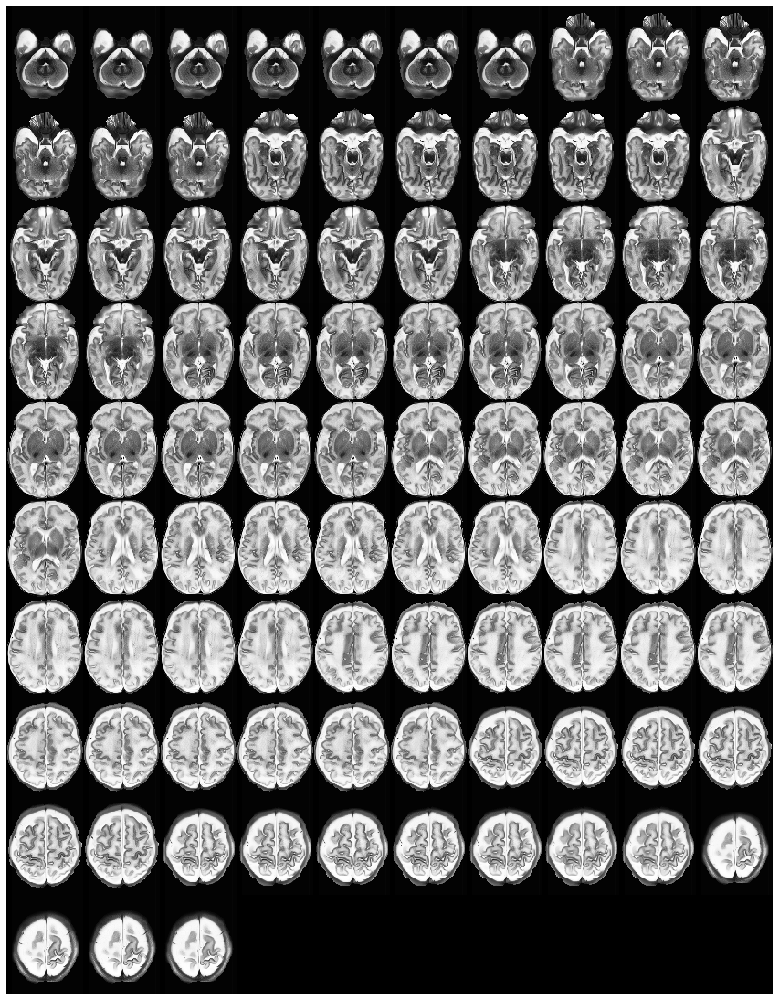

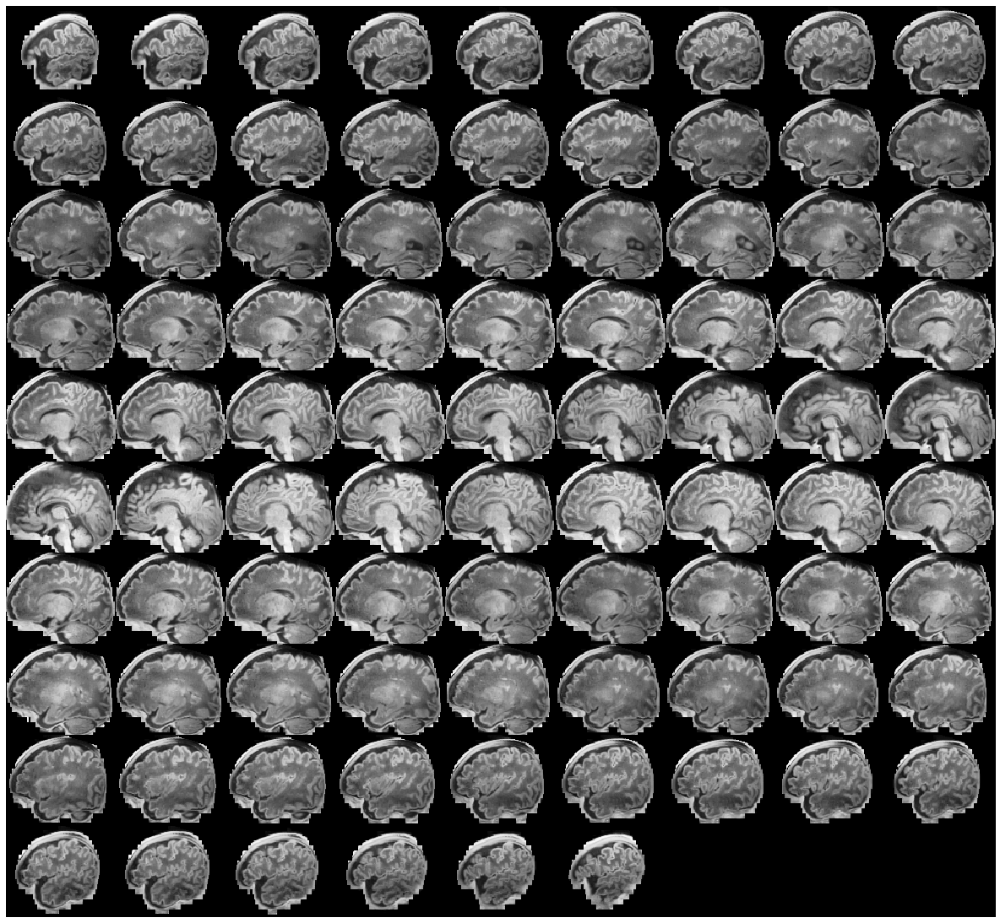

In [93]:
template_by_typical_case_t2 = enhan_image_modality_dict[635]['t2']
template_by_typical_case_t2.plot(nslices=93, axis=2)

template_by_typical_case_t1s = enhan_image_modality_dict[635]['t1s']
template_by_typical_case_t1s.plot(nslices=87, axis=0)

In [94]:
standard_dict = {}
for patient in enhan_image_modality_dict.keys():
    standard_dict[patient] = {}
    reg = ants.registration(template_by_typical_case_t2, 
                            enhan_image_modality_dict[patient]['t2'], type_of_transform='Affine')
    standard_dict[patient]['t2'] = reg['warpedmovout']    
    for i in ['t1', 't1s', 't2f', 'adc']: 
        standard_dict[patient][i] = ants.apply_transforms(template_by_typical_case_t2, 
                                                          enhan_image_modality_dict[patient][i], 
                                                          reg['fwdtransforms'])

In [95]:
view_slices = {}
for patient in standard_dict:
    target_mulmodal_slices = []
    for i in reversed(['t2f', 't2',  'adc', 't1']):
        target_slices = np.vstack([standard_dict[patient][i][:, :, 50], 
                                   standard_dict[patient][i][:, :, 51],
                                   standard_dict[patient][i][:, :, 52]])
        target_mulmodal_slices.append(target_slices)
    target_mulmodal_slices = np.hstack(target_mulmodal_slices)
    sag_target_slices = np.vstack([
                                   standard_dict[patient]['t1s'][33, :, :], 
                                   standard_dict[patient]['t1s'][34, :, :],
                                   standard_dict[patient]['t1s'][35, :, :]])
    view_slices[patient] = [target_mulmodal_slices, sag_target_slices]

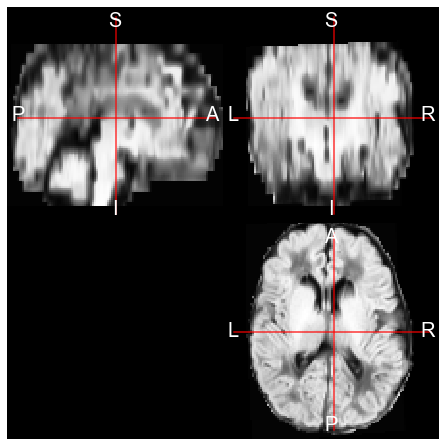

In [96]:
standard_dict[556]['t2f'].plot_ortho()

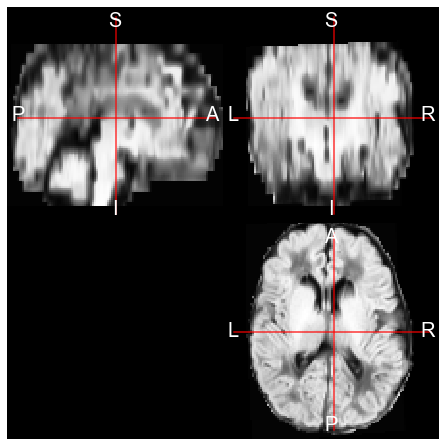

In [102]:
def reorient_slice(x, axis):
    if (axis != 2):
        x = rotate90_matrix(x)
    if (axis == 2):
        x = rotate270_matrix(x)
    x = mirror_matrix(x)
    return x

# ANTsPy/ants/viz: 1793 imslice = reorient_slice(imslice, axis)

test = standard_dict[556]['t2f'].reorient_image2('LAI')
test.plot_ortho()

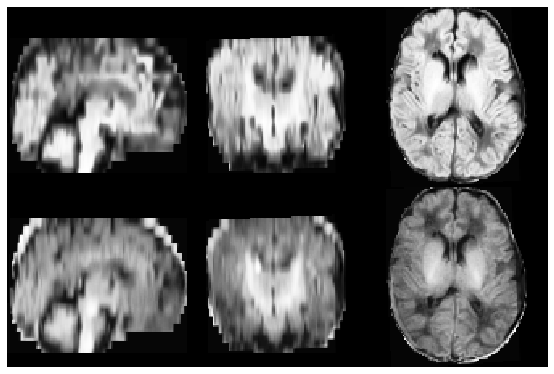

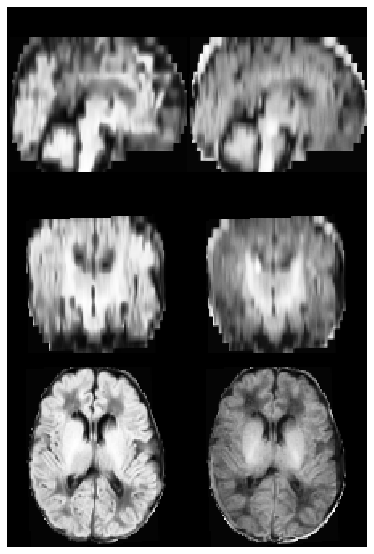

In [98]:
ants.plot_ortho_stack([standard_dict[556]['t2f'],  standard_dict[556]['t1']], transpose=False)
ants.plot_ortho_stack([standard_dict[556]['t2f'],  standard_dict[556]['t1']], transpose=True)

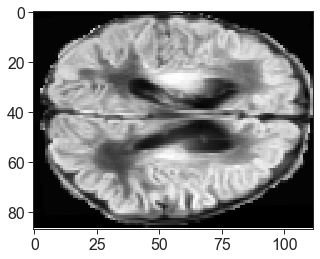

In [99]:
plt.imshow(standard_dict[556]['t2f'][:, :, 53], cmap=plt.cm.gray) # up: Left, down: Right

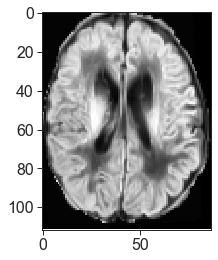

In [100]:
plt.imshow(np.rot90(standard_dict[556]['t2f'][:, :, 53]), cmap=plt.cm.gray)

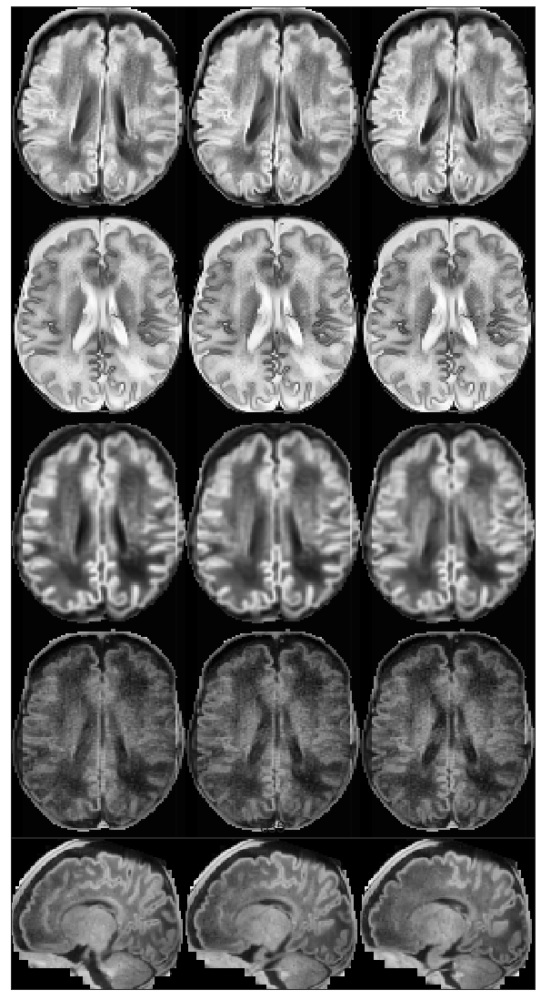

In [103]:
i = 635
fig = plt.figure(figsize=(8, 15))
gs = gridspec.GridSpec(2, 1, left=0, right=1, 
                       wspace=0.0, hspace=0.001, 
                       top=1, bottom=0, 
                       height_ratios=[5.5,1])

ax = plt.subplot(gs[0, 0])
ax.imshow(np.rot90(view_slices[i][0])[:, ::-1], 
          aspect='auto',
          #view_slices[i][0].shape[1]*4/view_slices[i][0].shape[0],
          interpolation='nearest', cmap=plt.cm.gray)
#ax.axis('image')
ax.set_xticks([])
ax.set_yticks([])
ax = plt.subplot(gs[1, 0])
ax.imshow(np.rot90(view_slices[i][1])[:, ::-1], 
          aspect='auto',
          #view_slices[i][1].shape[1]*4/view_slices[i][1].shape[0],
          interpolation='nearest', cmap=plt.cm.gray)
#ax.axis('image')
ax.set_xticks([])
ax.set_yticks([])
plt.title(i)        
plt.savefig('results/FigureS1.pdf')

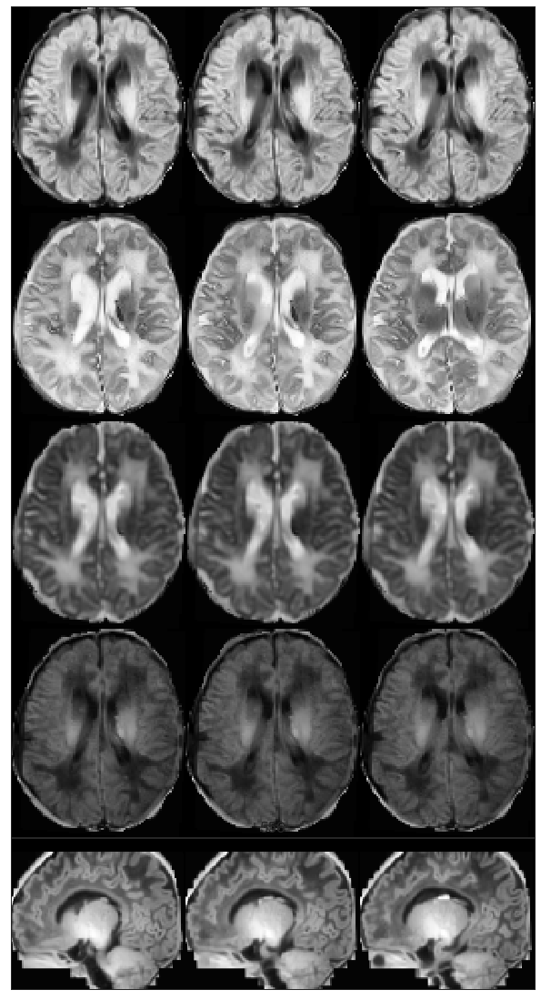

In [104]:
i = 556
fig = plt.figure(figsize=(8, 15))
gs = gridspec.GridSpec(2, 1, left=0, right=1, 
                       wspace=0.0, hspace=0.001, 
                       top=1, bottom=0, 
                       height_ratios=[5.5,1])

ax = plt.subplot(gs[0, 0])
ax.imshow(np.rot90(view_slices[i][0])[:, ::-1], 
          aspect='auto',
          #view_slices[i][0].shape[1]*4/view_slices[i][0].shape[0],
          interpolation='nearest', cmap=plt.cm.gray)
#ax.axis('image')
ax.set_xticks([])
ax.set_yticks([])
ax = plt.subplot(gs[1, 0])
ax.imshow(np.rot90(view_slices[i][1])[:, ::-1], 
          aspect='auto',
          #view_slices[i][1].shape[1]*4/view_slices[i][1].shape[0],
          interpolation='nearest', cmap=plt.cm.gray)
#ax.axis('image')
ax.set_xticks([])
ax.set_yticks([])
plt.title(i)        
plt.savefig('results/FigureS1.pdf')

In [105]:
standard_dict.keys()

dict_keys([635, 556, 101])

In [147]:
for i in [635, 556, 101]:
    for modal in ['t2f', 't2',  'adc', 't1', 't1s']:
        ants.image_write(standard_dict[i][modal], f'results/processed/{i}_{modal}_processed.nii.gz')

## Compare template

Loading both published and our template.

In [374]:
import ants

In [406]:
template_imperial = ants.image_read('../../../../data/Atlas/Regionalgrowth_and_atlas_Consistent_High_definition_Spatio-tempora/NeonatalAtlas2/template_T2_17.nii.gz')
template_unc = ants.image_read('../../../../data/Atlas/UNCInfant012Atlas_20140325/infant-1yr-withCerebellum.nii')
# our = ants.image_read('results/template_candidates/T_template0.nii.gz')
our = template_by_typical_case_t2 # use one case to represent template

In [407]:
our.shape

(87, 112, 93)

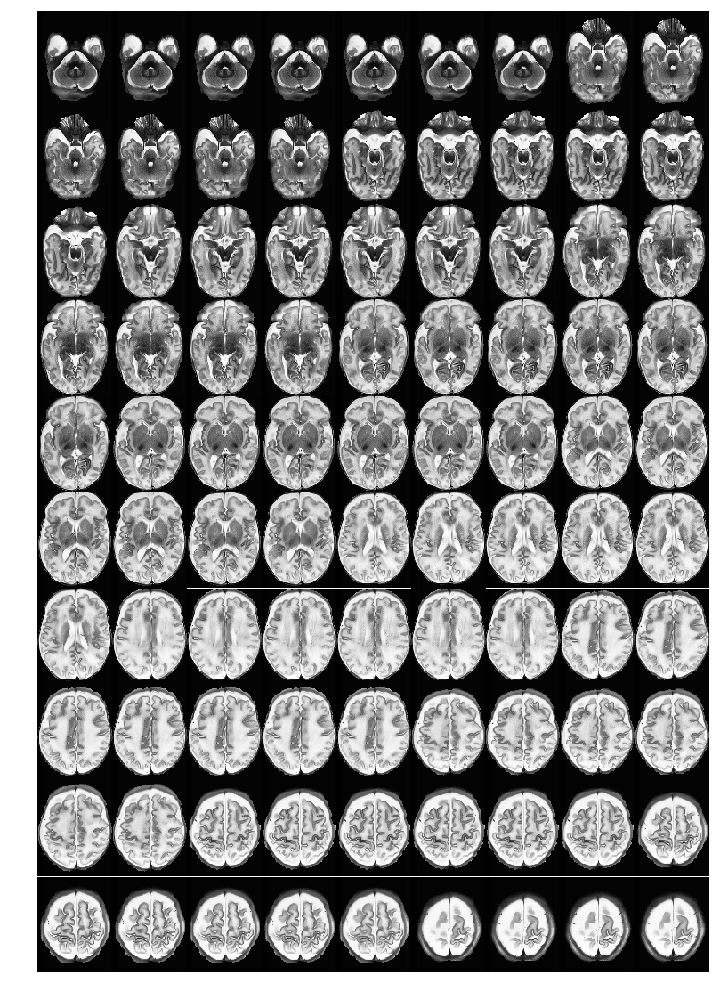

In [419]:
#ants.plot(our_9, nslices=80, axis=2)
ants.plot(our, nslices=90, axis=2)
#ants.plot(template_unc, axis=2)

In [409]:
def calc_brainvol(image):
    """cm*cm*cm"""
    return (image.get_mask()==1).sum() * np.prod(ants.get_spacing(image))/1000

In [466]:
##%%timeit
print('UNC average cm^3', calc_brainvol(template_unc))
print('Imperial 44weeks average cm^3', calc_brainvol(template_imperial))
print('Our 8 weeks average cm^3', calc_brainvol(our))

UNC average cm^3 1136.084
Imperial 44weeks average cm^3 541.3400921821594
Our 8 weeks average cm^3 358.132


## deploy all datasets to head1 for processing

1. process bids table into base file name
2. generate command lines

In [106]:
bids.shape

(1581, 18)

In [107]:
!mkdir -p results/raw

In [526]:
import copy
bids_copy = copy.deepcopy(bids)
def map_local_path(path):
    if 'genetics' in path:
        return os.path.join('results/raw/genetics', os.path.basename(path))
    elif 'new_sequence' in path:
        return os.path.join('results/raw/new_sequence', os.path.basename(path))
    elif 'xiamen' in path:
        return os.path.join('results/raw/xiamen', os.path.basename(path))
    elif 'Shanghai' in path and 'cont' in path:
        return os.path.join('results/raw/shanghai_cont', os.path.basename(path))
    elif 'Shanghai' in path and 'pvl' in path:
        return os.path.join('results/raw/shanghai_pvl', os.path.basename(path))
        
for modality in ['t1', 't1s', 't2', 'adc', 't2f']:        
    bids_copy.loc[:, modality] = bids_copy.loc[:, modality].map(map_local_path)

In [527]:
bids_copy.loc[:, 't1'].unique().shape

(1621,)

In [529]:
bids_copy.to_csv('results/bids_head1.csv')

In [525]:
with open('preprocess_head1.commands', 'w') as commands:
    for row in bids_copy.index:
    #     for modality in ['t1', 't1s', 't2', 'adc', 't2f']:
    #         !mkdir -p results/raw/{os.path.dirname(bids_copy.loc[row, modality])}
    #         !cp {bids.loc[row, modality]} results/raw/{bids_copy.loc[row, modality]}
        commands.write(f'python preprocess_with_casetemplate.py --bids results/bids_head1.csv --inputid {row} >> preprocess_head1.commands\n')

## check processed images

ADC images failed sometimes during Rigid and Affine registration by ANTsPy.

In [73]:
test_case1367 = ants.image_read('results/processed/1367_adc_processed.nii.gz')
raw1367 = ants.image_read('results/raw/shanghai_cont/sub-2618685_run-02_dwi.nii.gz')

In [74]:
raw1367.shape

(256, 256, 19)

In [75]:
raw1367_check = enhan_ants_image(raw1367, raw1367.get_mask())

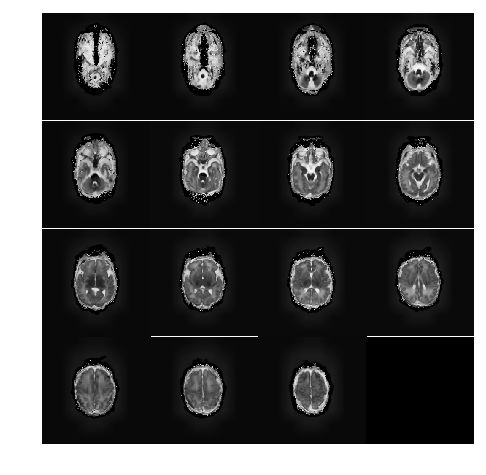

In [79]:
raw1367_check.plot(slices=range(15),axis=2)

In [81]:
raw1367_check = ants.bias_correction.abp_n4(raw1367)

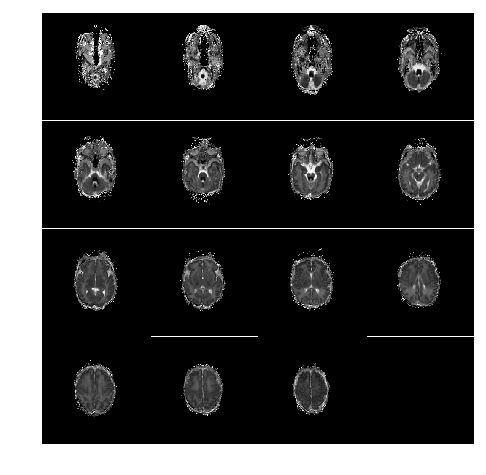

In [82]:
raw1367_check.plot(slices=range(15), axis=2)

In [96]:
#for candidate in template_candidates:
image_modality_dict = {}
for candidate in [1367]:

    t2_file = bids.loc[candidate, ].loc['t2']
    t2_prefix = t2_file.replace('.nii.gz', '_processed')
    !bet $t2_file $t2_prefix -m -R -f 0.4  

    image_modality_dict[candidate] = {}
    image_modality_dict[candidate]['t2'] = ants.image_read(t2_file)
    image_modality_dict[candidate]['t2'] = ants.resample_image(image_modality_dict[candidate]['t2'], (1,1,1), use_voxels=False)
    image_modality_dict[candidate]['mask'] = ants.image_read(f'{t2_prefix}_mask.nii.gz') 
    image_modality_dict[candidate]['mask'] = ants.resample_image(image_modality_dict[candidate]['mask'], 
                                                                (1,1,1), use_voxels=False)
    for modality in ['t1', 't1s', 't2f', 'adc']:
        image_modality_dict[candidate][modality] = ants.image_read(bids.loc[candidate, ].loc[modality])
        image_modality_dict[candidate][modality] = ants.registration(image_modality_dict[candidate]['t2'], 
                                                                     image_modality_dict[candidate][modality], 
                                                                     type_of_transform='Affine')
        image_modality_dict[candidate][modality] = image_modality_dict[candidate][modality]['warpedmovout']
#     for modality in ['t2', 't1', 't1s', 't2f', 'adc', 'mask']:
#         image_modality_dict[candidate][modality] = image_modality_dict[candidate][modality] * image_modality_dict[candidate]['mask']        
#         image_modality_dict[candidate][modality] = image_modality_dict[candidate][modality].crop_image(image_modality_dict[candidate]['mask'])

## Experiment with FSL version of pipeline

In [8]:
def get_crop(mat):
    """ find first slice with non-zero voxels in each dimension borrow from NeBSS"""
    for i in range(mat.shape[0]):
        xmin = i
        if np.sum(mat[i, :, :]) > 0:
                break
    for i in range(mat.shape[0]-1, 0, -1):
        xmax = i
        if np.sum(mat[i, :, :]) > 0:
                break
    for i in range(mat.shape[1]):
        ymin = i
        if np.sum(mat[:, i, :]) > 0:
                break
    for i in range(mat.shape[1]-1, 0, -1):
        ymax = i
        if np.sum(mat[:, i, :]) > 0:
                break
    for i in range(mat.shape[2]):
        zmin = i
        if np.sum(mat[:, :, i]) > 0:
                break
    for i in range(mat.shape[2]-1, 0, -1):
        zmax = i
        if np.sum(mat[:, :, i]) > 0:
                break
    return xmin,xmax,ymin,ymax,zmin,zmax

In [221]:
def crop_enhan_ants_image(ants_image, mask, clip_limit=0.015):
    import numpy as np
    from skimage import exposure, img_as_int
    from skimage.restoration import denoise_wavelet

    im = ants_image.crop_image(mask)
    im = im.denoise_image()    
    mask = mask.crop_image(mask)    
 
#further crop images
#     im = im * mask
#     mask = im.get_mask()    
#    im = im.crop_image(mask)
#    mask = mask.crop_image(mask)
    
    imdata = im.numpy()
    imshape = im.shape

    immin = imdata.min()
    imdata = (imdata - immin).astype(np.uint16)

    adapted = exposure.equalize_adapthist(
        denoise_wavelet(imdata.reshape(imshape[0], -1)), clip_limit=clip_limit)
    
    adapted_image = adapted.reshape(imshape)
    return ants.make_image(mask.shape, voxval=adapted_image, 
                           spacing=(1,1,1), 
                           direction=ants.get_direction(mask), 
                           origin=ants.get_origin(mask))

In [160]:
template_candidates = [635, 1367] ## adc is processed badly

for candidate in template_candidates:
    adc = bids.loc[candidate, ].loc['adc']
    t2 = bids.loc[candidate, ].loc['t2']
    t2f = bids.loc[candidate, ].loc['t2f']    
    t1s = bids.loc[candidate, ].loc['t1s']
    t1 = bids.loc[candidate, ].loc['t1']    
    
    t2_prefix = t2.replace('.nii.gz', '_processed')
    adc_prefix = adc.replace('.nii.gz', '_processed')
    t2f_prefix = t2f.replace('.nii.gz', '_processed')
    t1s_prefix = t1s.replace('.nii.gz', '_processed')
    t1_prefix = t1.replace('.nii.gz', '_processed')

    !fslreorient2std {t2} {t2_prefix}_reoriented.nii.gz                
    !flirt -datatype float -interp spline -in {t2_prefix}_reoriented.nii.gz -ref {t2_prefix}_reoriented.nii.gz -applyisoxfm 1 -out {t2_prefix}.nii.gz    
    !fslreorient2std {adc} {adc_prefix}_reoriented.nii.gz        
    !flirt -dof 6 -in {adc_prefix}_reoriented.nii.gz -ref {t2_prefix}.nii.gz -out {adc_prefix}.nii.gz    
    !fslreorient2std {t1} {t1_prefix}_reoriented.nii.gz    
    !flirt -coarsesearch 90 -finesearch 90 -dof 6 -in {t1_prefix}_reoriented.nii.gz -ref {t2_prefix}.nii.gz -out {t1_prefix}.nii.gz    
    !fslreorient2std {t1s} {t1s}_reoriented.nii.gz    
    !flirt -coarsesearch 90 -finesearch 90 -dof 6 -in {t1s}_reoriented.nii.gz -ref {t2_prefix}.nii.gz -out {t1s_prefix}.nii.gz
    !fslreorient2std {t2f} {t2f_prefix}_reoriented.nii.gz
    !flirt -dof 6 -in {t2f_prefix}_reoriented.nii.gz -ref {t2_prefix}.nii.gz -out {t2f_prefix}.nii.gz        
    !bet {t2_prefix} {t2_prefix} -m -R -f 0.4


Final result: 
0.999991 -0.003715 -0.001821 0.600265 
0.003706 0.999982 -0.004654 -2.122054 
0.001838 0.004647 0.999988 -2.480929 
0.000000 0.000000 0.000000 1.000000 


Final result: 
1.000000 0.000000 0.000000 0.255768 
0.000000 1.000000 -0.000773 -0.185388 
0.000000 0.000773 1.000000 -0.001900 
0.000000 0.000000 0.000000 1.000000 


Final result: 
0.999779 -0.010874 0.017969 -6.256810 
0.016008 0.948353 -0.316812 17.472794 
-0.013596 0.317030 0.948318 -40.366344 
0.000000 0.000000 0.000000 1.000000 


Final result: 
0.999998 0.000000 0.002012 0.132328 
0.000004 0.999998 -0.002095 -0.173473 
-0.002012 0.002095 0.999996 -0.058849 
0.000000 0.000000 0.000000 1.000000 


Final result: 
0.999698 0.024561 0.000424 -2.269970 
-0.023930 0.969831 0.242599 -2.339788 
0.005547 -0.242536 0.970126 26.046216 
0.000000 0.000000 0.000000 1.000000 


Final result: 
1.000000 0.000000 0.000000 0.162317 
0.000000 0.999989 0.004591 -1.188626 
0.000000 -0.004591 0.999989 0.682607 
0.000000 0.000000 0.00

(239, 239, 94)


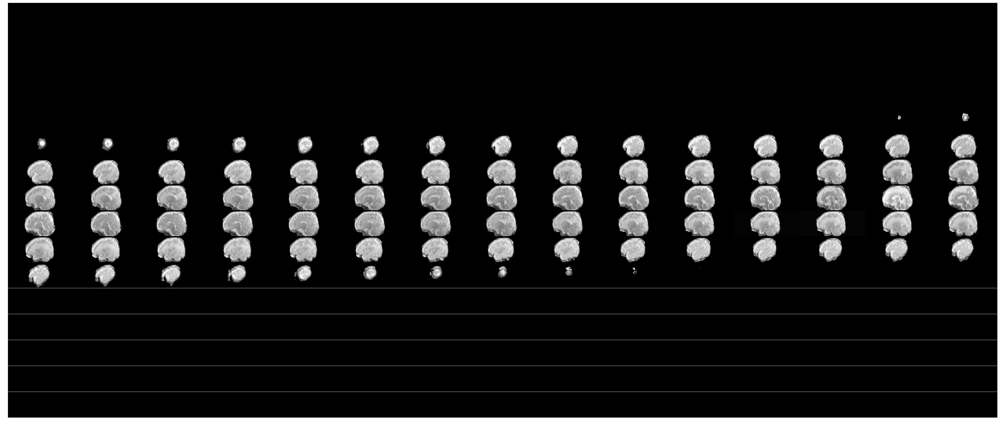

In [161]:
t2 = bids.loc[635, ].loc['t2']    
t2_prefix = t2.replace('.nii.gz', '_processed')
test_t2 = ants.image_read(f'{t2_prefix}.nii.gz')
print(test_t2.shape)
test_t2.plot(axis=0, slices=range(239))

(239, 239, 94)


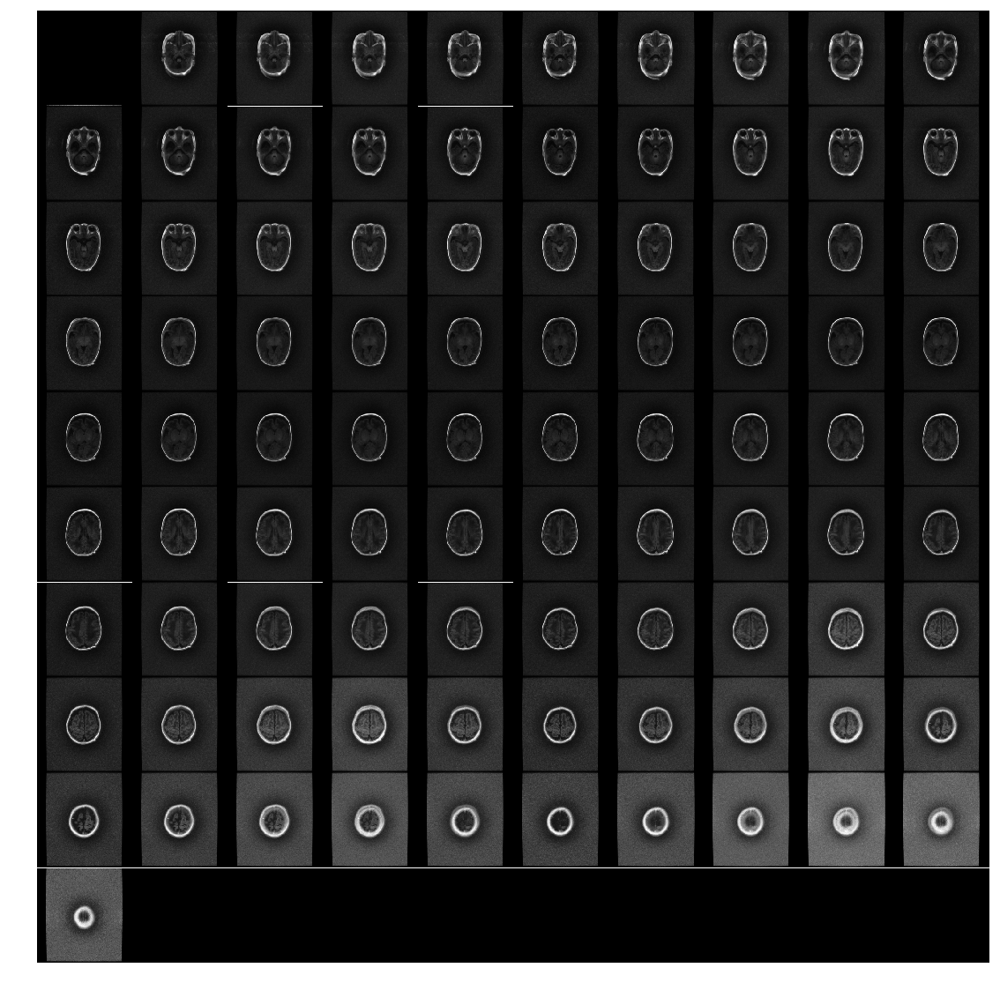

In [154]:
t1 = bids.loc[635, ].loc['t1']    
t1_prefix = t1.replace('.nii.gz', '_processed')
test_t1 = ants.image_read(f'{t1_prefix}.nii.gz')
print(test_t1.shape)
test_t1.plot(axis=2, slices=range(93))

In [222]:
for candidate in template_candidates:
    for modality in ['t2','t1', 't1s', 't2f', 'adc']:
        image_file = bids.loc[candidate, ].loc[modality]
        image_prefix = image_file.replace('.nii.gz', '_processed')
        
        image = ants.image_read(f'{image_prefix}.nii.gz')        
        mask  = ants.image_read(bids.loc[candidate, ].loc['t2'].replace('.nii.gz', '_processed_mask.nii.gz'))
        
        image = crop_enhan_ants_image(image, mask)
        ants.image_write(image, f'{image_prefix}_crop_enhance.nii.gz')
        print(image.shape)

/home/qinqian/.local/lib/python3.6/site-packages/pywt/_multilevel.py:408: FutureWarning:

Using a non-tuple sequence for multidimensional indexing is deprecated; use `arr[tuple(seq)]` instead of `arr[seq]`. In the future this will be interpreted as an array index, `arr[np.array(seq)]`, which will result either in an error or a different result.

/home/qinqian/.local/lib/python3.6/site-packages/skimage/util/dtype.py:135: UserWarning:

Possible precision loss when converting from float64 to uint16



(88, 113, 92)
(88, 113, 92)
(88, 113, 92)
(88, 113, 92)
(88, 113, 92)
(84, 108, 85)
(84, 108, 85)
(84, 108, 85)
(84, 108, 85)
(84, 108, 85)


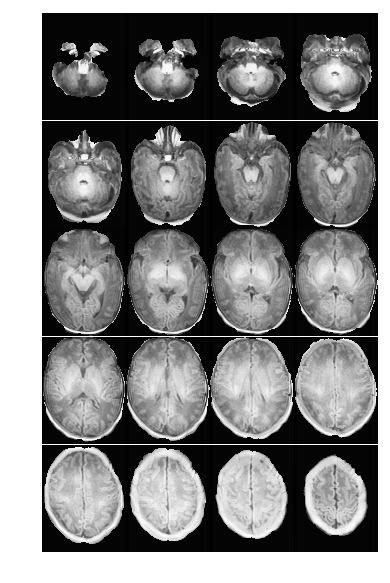

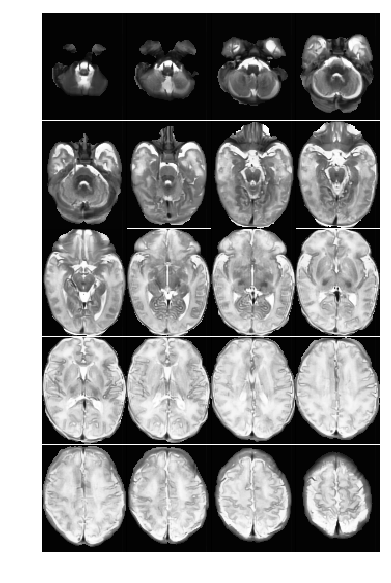

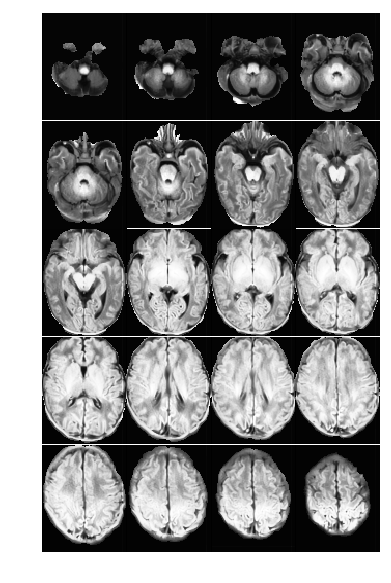

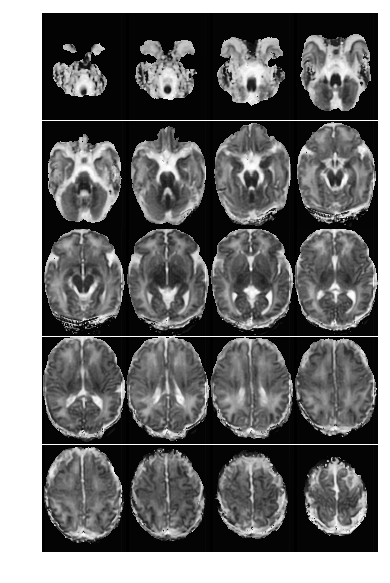

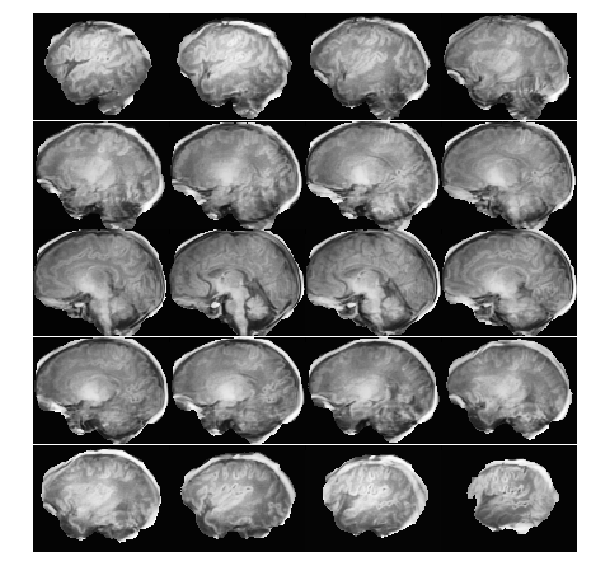

In [220]:
candidate = template_candidates[1]
for modality in ['t1', 't2', 't2f', 'adc', 't1s']:
    image_file = bids.loc[candidate, ].loc[modality]
    image_prefix = image_file.replace('.nii.gz', '_processed')

    test = ants.image_read(f'{image_prefix}_crop_enhance.nii.gz')
    if modality == 't1s':        
        test.plot(axis=0, nslices=20)
    else:
        test.plot(axis=2, nslices=20)

(256, 256, 3)


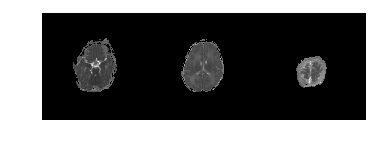

In [46]:
import ants, os
adc_prefix = 'results/processed/483_adc_processed'
print(ants.image_read(bids.loc[483, 'adc']).shape)
ants.image_read(bids.loc[483, 'adc']).plot(axis=2, slices=range(3))
ants.image_read(f'{adc_prefix}.nii.gz').plot(axis=2, slices=range(19))

## Add filters on template


In [24]:
t2_635 = ants.image_read('results/processed/635_t2_processed.nii.gz')
template_imperial = ants.image_read('../../../../data/Atlas/Regionalgrowth_and_atlas_Consistent_High_definition_Spatio-tempora/NeonatalAtlas2/template_T2_17.nii.gz')
mask = ants.image_read('../../../../data/Atlas/Regionalgrowth_and_atlas_Consistent_High_definition_Spatio-tempora/NeonatalAtlas2/brainmask_17.nii.gz')
stem = ants.image_read('../../../../data/Atlas/Regionalgrowth_and_atlas_Consistent_High_definition_Spatio-tempora/NeonatalAtlas2/brainstem_17.nii.gz')
cerebellum = ants.image_read('../../../../data/Atlas/Regionalgrowth_and_atlas_Consistent_High_definition_Spatio-tempora/NeonatalAtlas2/cerebellum_17.nii.gz')
csf = ants.image_read('../../../../data/Atlas/Regionalgrowth_and_atlas_Consistent_High_definition_Spatio-tempora/NeonatalAtlas2/csf_17.nii.gz')

In [10]:
reg = ants.registration(t2_635, template_imperial)

In [25]:
mask = ants.apply_transforms(t2_635, mask, reg['fwdtransforms'])
stem = ants.apply_transforms(t2_635, stem, reg['fwdtransforms'])
cerebellum = ants.apply_transforms(t2_635, cerebellum, reg['fwdtransforms'])
csf = ants.apply_transforms(t2_635, csf, reg['fwdtransforms'])

In [26]:
t2_635.shape

(87, 112, 93)

In [30]:
t2_635[:, :, 14:(93-17)].shape

(87, 112, 62)

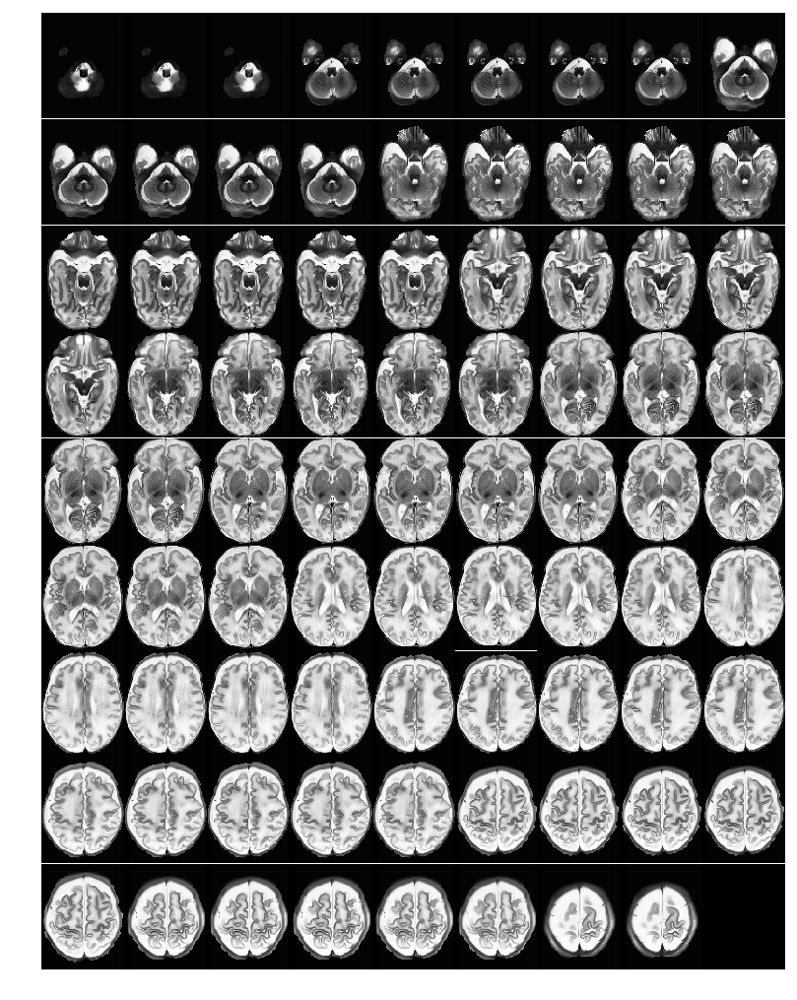

In [27]:
t2_635.plot(axis=2, slices=range(80))

## apply brain mask and csf from standard template published by imperial college

In [42]:
t2_635_thresh = t2_635*ants.threshold_image(mask.image_math('GE', 2)+ants.threshold_image(csf, 0, 0.6), 1, 2)

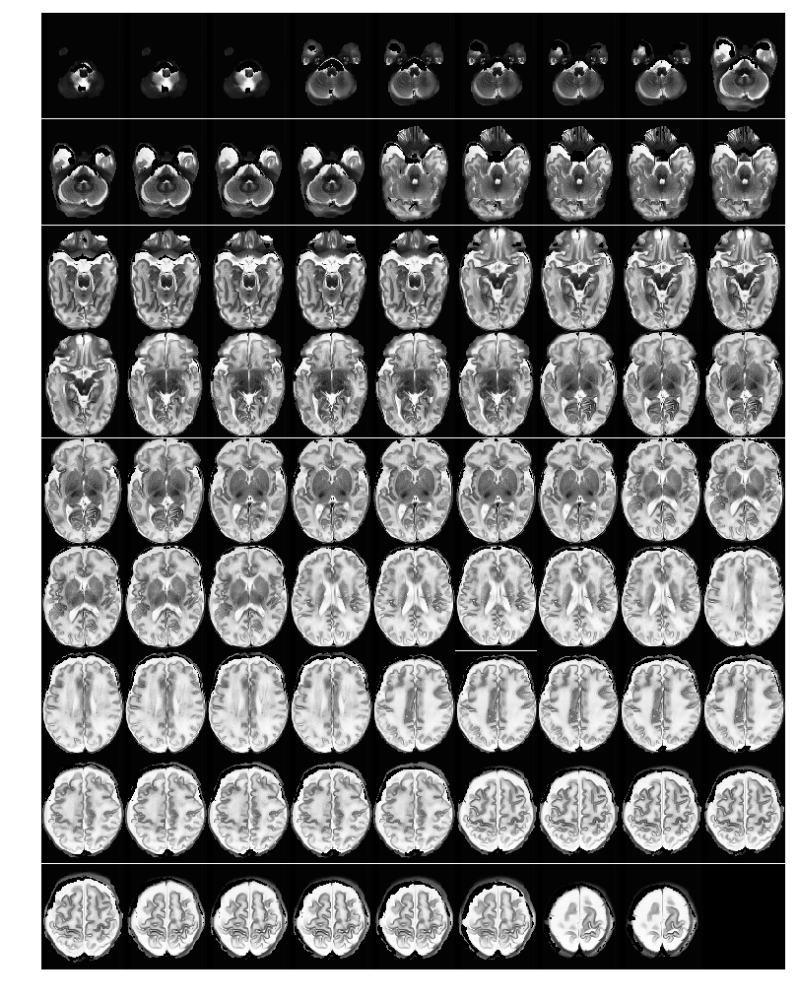

In [43]:
t2_635_thresh.plot(axis=2, slices=range(80))

In [33]:
t2_635_thresh = t2_635*ants.threshold_image(mask.image_math('GE', 2))

## Supp Fig 1 and Merge template

Since building template with ants shell scripts does not work so well, and the affine transformation seems ok, we merged template based on the affine transformed images at age 8 weeks.

In [153]:
enhan_image_modality_dict = {}
for i in [635, 556, 101]:
    enhan_image_modality_dict[i] = {}
    for modal in ['t2f', 't2',  'adc', 't1', 't1s']:
        enhan_image_modality_dict[i][modal] = ants.image_read(f'results/processed/{i}_{modal}_processed.nii.gz')

In [182]:
view_slices = {}
for patient in enhan_image_modality_dict:
    target_mulmodal_slices = []
    for i in reversed(['t2f', 't2', 'adc', 't1']):
        target_slices = np.vstack([enhan_image_modality_dict[patient][i][:, :, 60], 
                                   enhan_image_modality_dict[patient][i][:, :, 61],
                                   enhan_image_modality_dict[patient][i][:, :, 62]])
        target_mulmodal_slices.append(target_slices)
    target_mulmodal_slices = np.hstack(target_mulmodal_slices)
    sag_target_slices = np.vstack([
                                   enhan_image_modality_dict[patient]['t1s'][32, :, :], 
                                   enhan_image_modality_dict[patient]['t1s'][36, :, :],
                                   enhan_image_modality_dict[patient]['t1s'][40, :, :]])
    view_slices[patient] = [target_mulmodal_slices, sag_target_slices]

/home/qinqian/.local/lib/python3.6/site-packages/numpy/lib/type_check.py:546: DeprecationWarning:

np.asscalar(a) is deprecated since NumPy v1.16, use a.item() instead



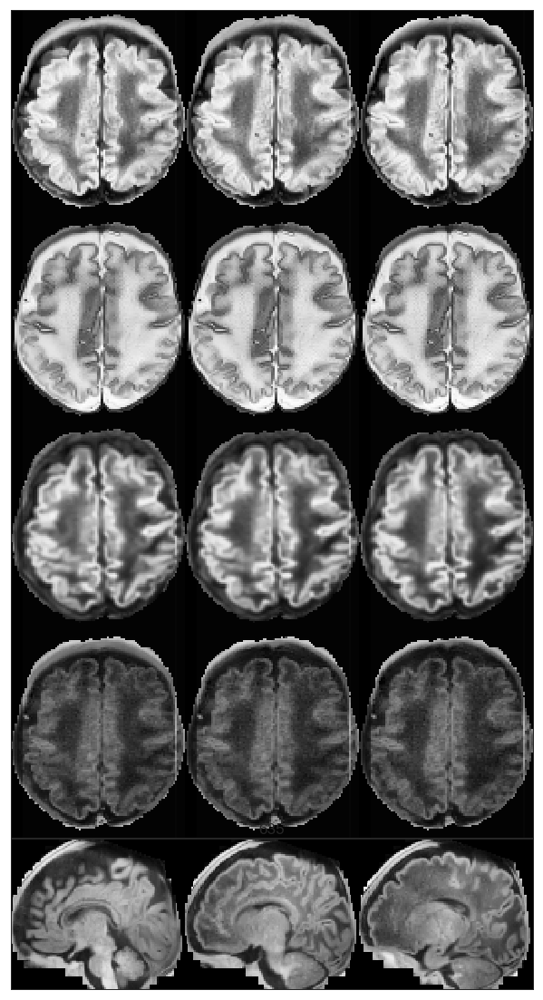

In [183]:
i = 635
fig = plt.figure(figsize=(8, 15))
gs = gridspec.GridSpec(2, 1, left=0, right=1, 
                       wspace=0.0, hspace=0.001, 
                       top=1, bottom=0, 
                       height_ratios=[5.5,1])

ax = plt.subplot(gs[0, 0])
ax.imshow(np.rot90(view_slices[i][0])[:, ::-1], 
          aspect='auto',
          #view_slices[i][0].shape[1]*4/view_slices[i][0].shape[0],
          interpolation='nearest', cmap=plt.cm.gray)
#ax.axis('image')
ax.set_xticks([])
ax.set_yticks([])
ax = plt.subplot(gs[1, 0])
ax.imshow(np.rot90(view_slices[i][1])[:, ::-1], 
          aspect='auto',
          #view_slices[i][1].shape[1]*4/view_slices[i][1].shape[0],
          interpolation='nearest', cmap=plt.cm.gray)
#ax.axis('image')
ax.set_xticks([])
ax.set_yticks([])
plt.title(i)        
plt.savefig('results/FigureS1_1.pdf')

/home/qinqian/.local/lib/python3.6/site-packages/numpy/lib/type_check.py:546: DeprecationWarning:

np.asscalar(a) is deprecated since NumPy v1.16, use a.item() instead



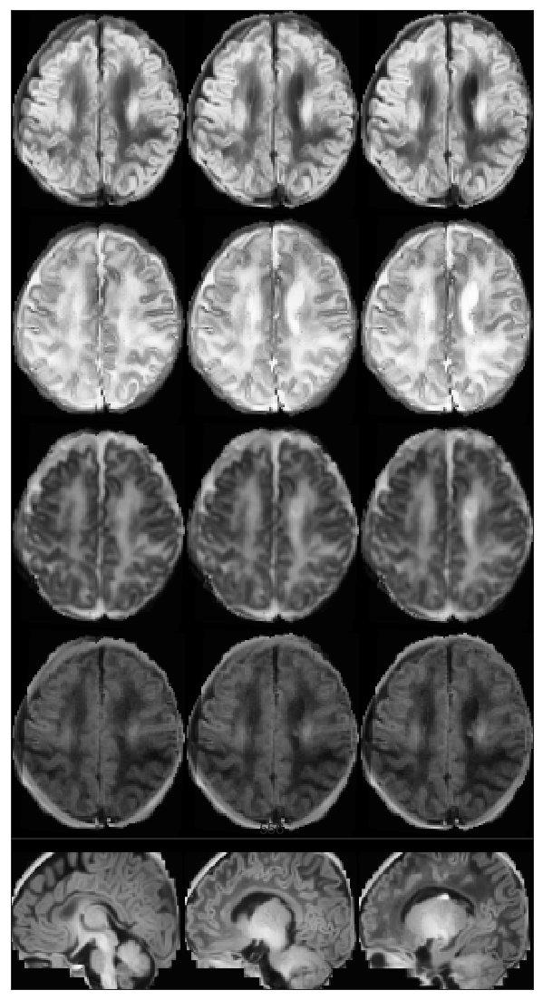

In [184]:
i = 556
fig = plt.figure(figsize=(8, 15))
gs = gridspec.GridSpec(2, 1, left=0, right=1, 
                       wspace=0.0, hspace=0.001, 
                       top=1, bottom=0, 
                       height_ratios=[5.5,1])

ax = plt.subplot(gs[0, 0])
ax.imshow(np.rot90(view_slices[i][0])[:, ::-1], 
          aspect='auto',
          #view_slices[i][0].shape[1]*4/view_slices[i][0].shape[0],
          interpolation='nearest', cmap=plt.cm.gray)
#ax.axis('image')
ax.set_xticks([])
ax.set_yticks([])
ax = plt.subplot(gs[1, 0])
ax.imshow(np.rot90(view_slices[i][1])[:, ::-1], 
          aspect='auto',
          #view_slices[i][1].shape[1]*4/view_slices[i][1].shape[0],
          interpolation='nearest', cmap=plt.cm.gray)
#ax.axis('image')
ax.set_xticks([])
ax.set_yticks([])
plt.title(i)        
plt.savefig('results/FigureS1_2.pdf')

In [172]:
case2 = bids.loc[bids.age == 8, :]

In [173]:
case2.shape

(133, 18)

In [174]:
exclude = "check_datasets/bad_ids_thrown_ids_for_antspy2.txt"
with open(exclude) as fin:
    exclude_ids = list(map(int, fin.readlines()))
    
case2 = case2.loc[~case2.index.isin(exclude_ids), :]

In [176]:
all_template = {}
for modality in ['t1', 't1s', 't2f', 't2', 'adc']:
    template_custom = {}    
    for i in case2.index:    
        template_custom[i] = ants.image_read(f'results/processed/{i}_{modality}_processed.nii.gz')
        
    image = template_custom[list(template_custom.keys())[0]]
    for i in list(template_custom.keys())[1:]:
        image += template_custom[i]
    image = image/len(template_custom.keys())
    all_template[modality] = image

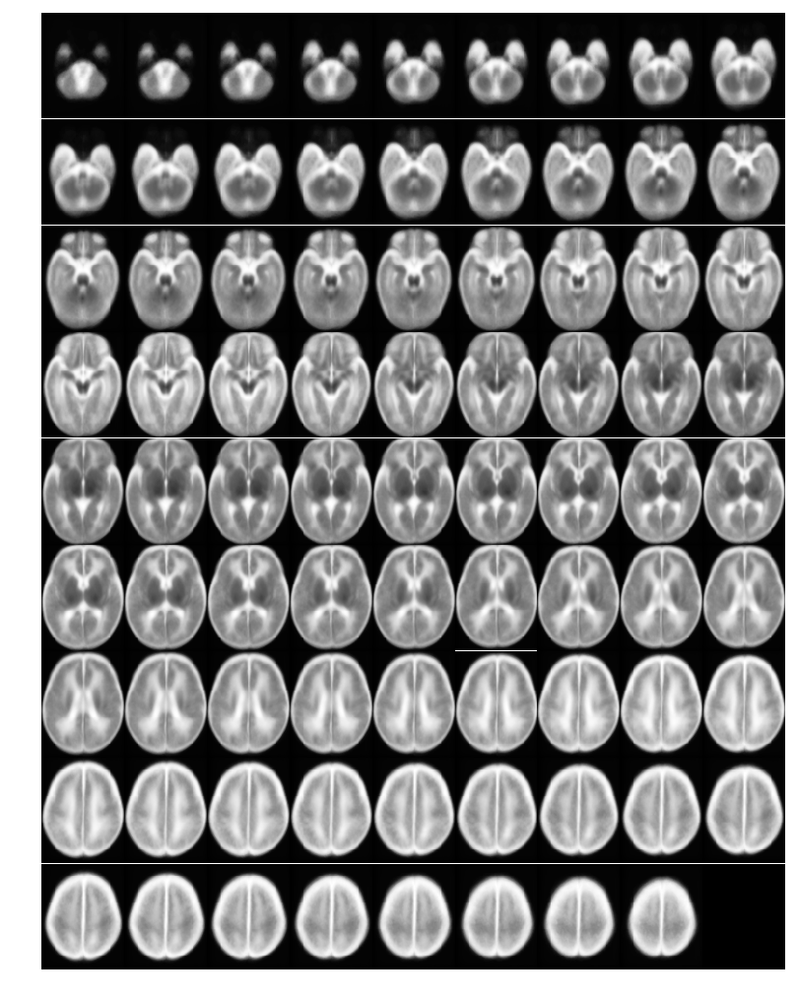

In [177]:
all_template['adc'].plot(axis=2, slices=range(80))

In [178]:
target_mulmodal_slices = []
for i in reversed(['t2f', 't2', 'adc', 't1']):
    target_slices = np.vstack([all_template[i][:, :, 60], 
                               all_template[i][:, :, 61],
                               all_template[i][:, :, 62]])
    target_mulmodal_slices.append(target_slices)
target_mulmodal_slices = np.hstack(target_mulmodal_slices)
sag_target_slices = np.vstack([
                               all_template['t1s'][32, :, :], 
                               all_template['t1s'][36, :, :],
                               all_template['t1s'][40, :, :]])
view_slices = [target_mulmodal_slices, sag_target_slices]

/home/qinqian/.local/lib/python3.6/site-packages/numpy/lib/type_check.py:546: DeprecationWarning:

np.asscalar(a) is deprecated since NumPy v1.16, use a.item() instead



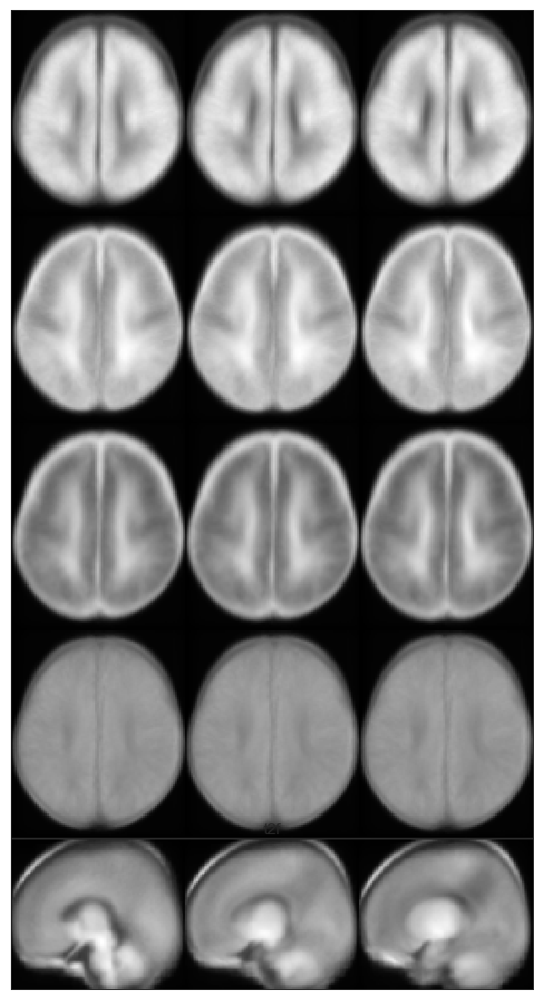

In [180]:
fig = plt.figure(figsize=(8, 15))
gs = gridspec.GridSpec(2, 1, left=0, right=1, 
                       wspace=0.0, hspace=0.001, 
                       top=1, bottom=0, 
                       height_ratios=[5.5,1])

ax = plt.subplot(gs[0, 0])
ax.imshow(np.rot90(view_slices[0])[:, ::-1], 
          aspect='auto',
          #view_slices[i][0].shape[1]*4/view_slices[i][0].shape[0],
          interpolation='nearest', cmap=plt.cm.gray)
#ax.axis('image')
ax.set_xticks([])
ax.set_yticks([])
ax = plt.subplot(gs[1, 0])
ax.imshow(np.rot90(view_slices[1])[:, ::-1], 
          aspect='auto',
          #view_slices[i][1].shape[1]*4/view_slices[i][1].shape[0],
          interpolation='nearest', cmap=plt.cm.gray)
#ax.axis('image')
ax.set_xticks([])
ax.set_yticks([])
plt.title(i)        
plt.savefig('results/FigureS1_3.pdf')

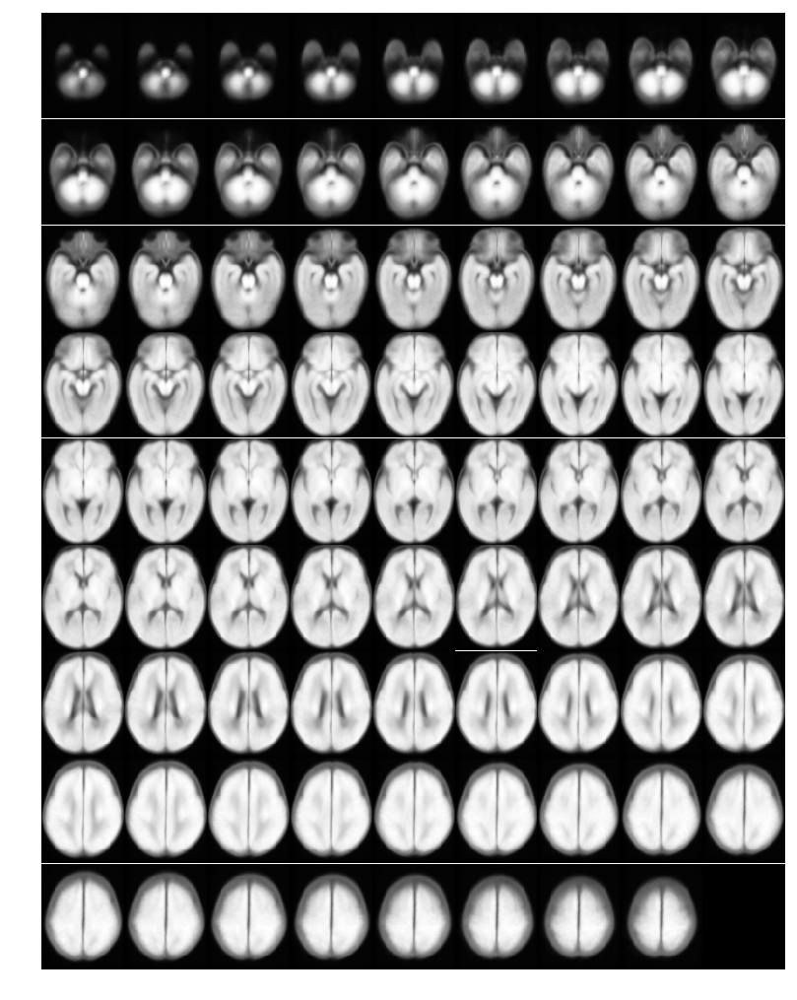

In [199]:
all_template['t2f'].plot(axis=2, slices=range(80))

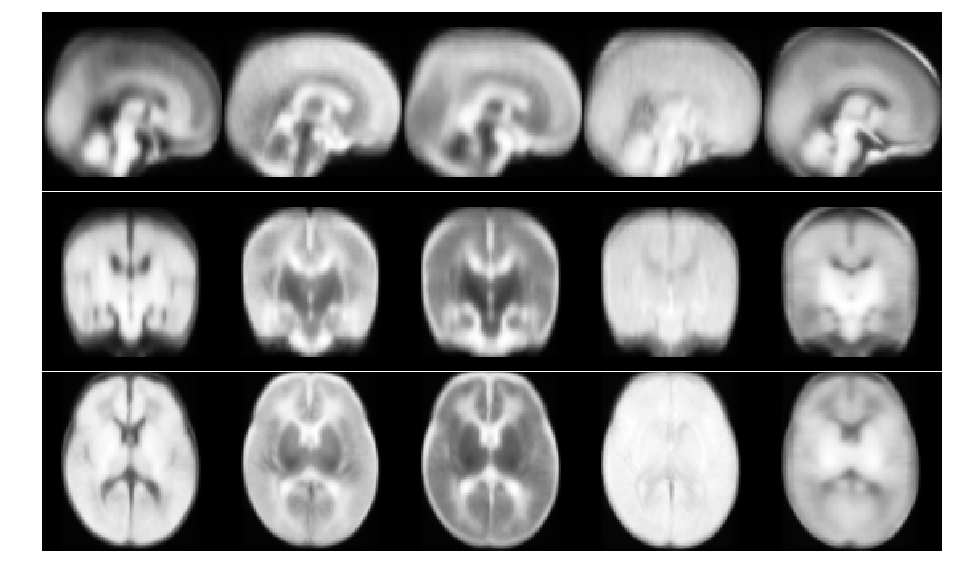

In [206]:
#ants.plot_ortho_stack([ all_template[t] for t in ['t2f', 't2', 'adc', 't1', 't1s'] ], filename='results/FigureS1_3.pdf')
ants.plot_ortho_stack([ all_template[t] for t in ['t2f', 't2', 'adc', 't1', 't1s'] ], transpose=True)

In [195]:
!mkdir -p results/template
for t in ['t2f', 't2', 'adc', 't1', 't1s']:
    ants.image_write(all_template[t], 'results/template/8weeks_%s.nii.gz' % t)

## do not apply cerebellum and stem 

In [99]:
#t2_635_thresh = t2_635_thresh*ants.threshold_image(stem, 0, 0.4999)

In [120]:
t2_635_thresh = t2_635_thresh*ants.threshold_image(cerebellum, 0, 0.1)

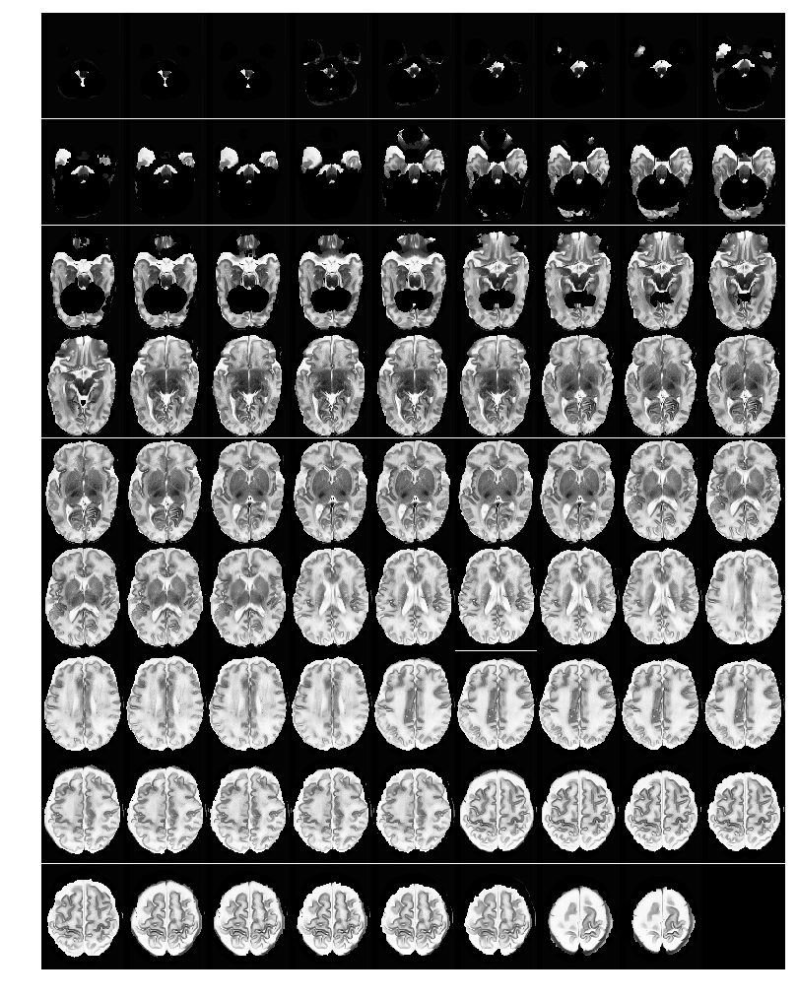

In [119]:
t2_635_thresh.plot(axis=2, slices=range(80))

## Useful visualization of models


In [24]:
import xgboost

In [25]:
import shap

In [26]:
# train XGBoost model
X,y = shap.datasets.boston()
model = xgboost.train({"learning_rate": 0.01}, xgboost.DMatrix(X, label=y), 100)

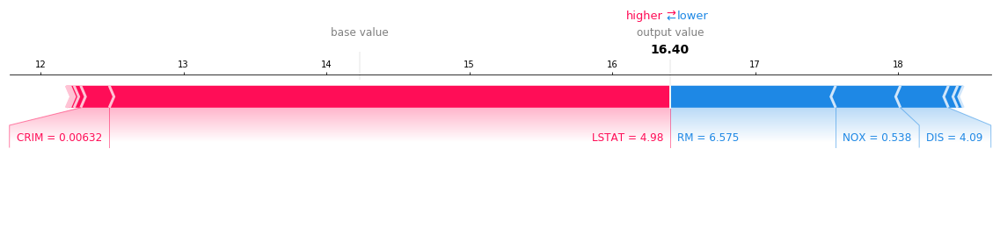

In [27]:
# explain the model's predictions using SHAP values
# (same syntax works for LightGBM, CatBoost, and scikit-learn models)
explainer = shap.TreeExplainer(model)
shap_values = explainer.shap_values(X)

# visualize the first prediction's explanation (use matplotlib=True to avoid Javascript)
shap.force_plot(explainer.expected_value, shap_values[0,:], X.iloc[0,:], matplotlib=True)

## Import tensorflow.keras.<something>.<something>

In [47]:
from tensorflow.keras.applications.vgg16 import VGG16
from keras.applications.vgg16 import preprocess_input
import keras.backend as K

from tensorflow.keras.backend import backend
import numpy as np
import json
import shap

In [18]:
# load pre-trained model and choose two images to explain
model = VGG16(weights='imagenet', include_top=True)

In [19]:
model.summary()

Model: "vgg16"
_________________________________________________________________
Layer (type)                 Output Shape              Param #   
input_2 (InputLayer)         [(None, 224, 224, 3)]     0         
_________________________________________________________________
block1_conv1 (Conv2D)        (None, 224, 224, 64)      1792      
_________________________________________________________________
block1_conv2 (Conv2D)        (None, 224, 224, 64)      36928     
_________________________________________________________________
block1_pool (MaxPooling2D)   (None, 112, 112, 64)      0         
_________________________________________________________________
block2_conv1 (Conv2D)        (None, 112, 112, 128)     73856     
_________________________________________________________________
block2_conv2 (Conv2D)        (None, 112, 112, 128)     147584    
_________________________________________________________________
block2_pool (MaxPooling2D)   (None, 56, 56, 128)       0     

In [20]:
X,y = shap.datasets.imagenet50()

In [21]:
to_explain = X[[39,41]]

## Explore another labels

In [10]:
Hemorrhage = bids.loc[(bids.Leukomalacia == 0) & (bids.Hemorrhage == 1), :]

In [18]:
z=ants.image_read('results/processed/9_t2f_processed.nii.gz')

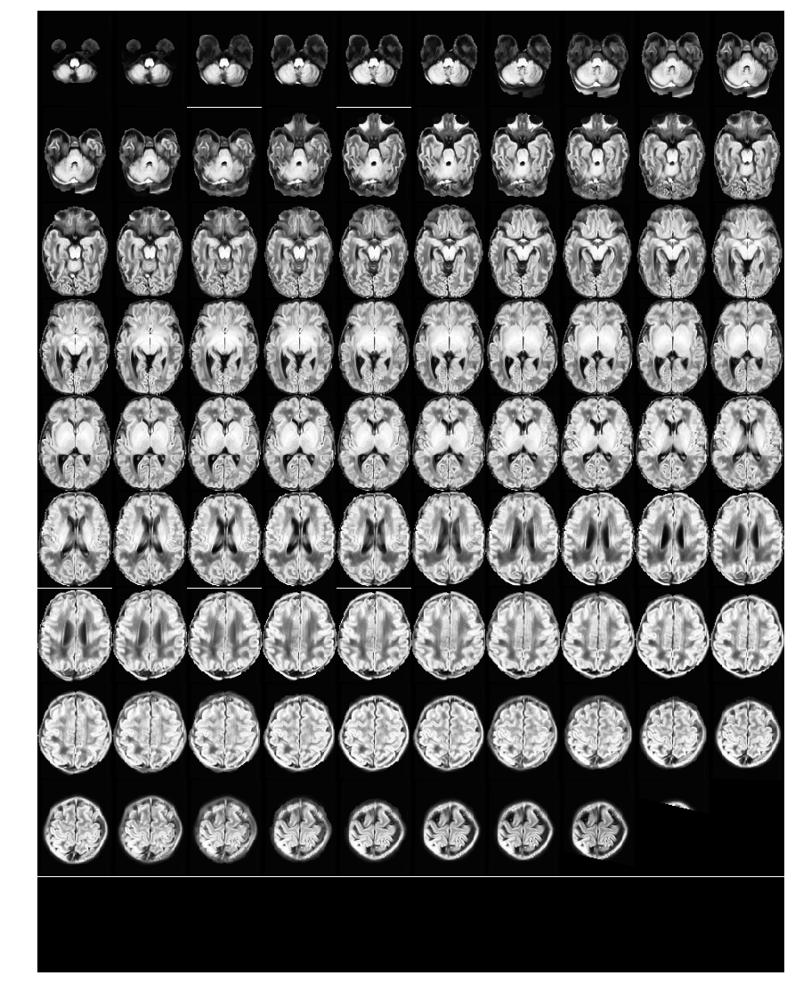

In [20]:
z.plot(axis=2, slices=range(93))

In [27]:
z=ants.image_read(Hemorrhage.iloc[0, :].loc['t2f'])

In [28]:
z=z.crop_image(z.get_mask())

z.plot(axis=2, slices=range(17), figsize=4, dpi=1000)

## Hemorrhage seems to have more variance which is hard to predict.

## Prepare Fig. 1A

In [35]:
test_case1 = bids.loc[(bids.Leukomalacia==1) & (bids.loc[:, 'pvl.label']=='1-3'), :].index[0]

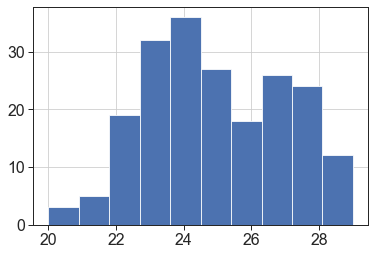

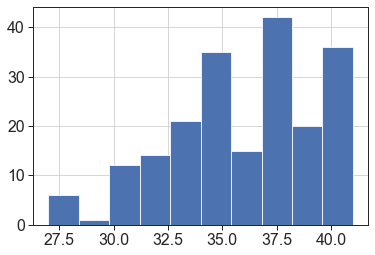

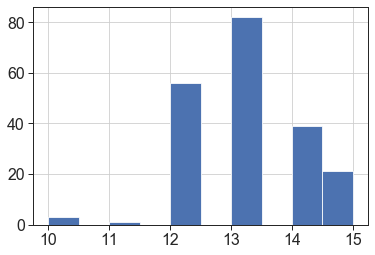

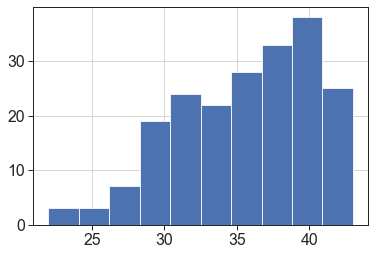

In [34]:
plt.figure()
bids.loc[:, 'Fine Motor_12m'].hist()
plt.figure()
bids.loc[:, 'Cognitive_12m'].hist()
plt.figure()
bids.loc[:, 'Receptive Communication_12m'].hist()
plt.figure()
bids.loc[:, 'Gross Motor_12m'].hist()

## show the raw image of five modalities

[0, 5, 10, 13]


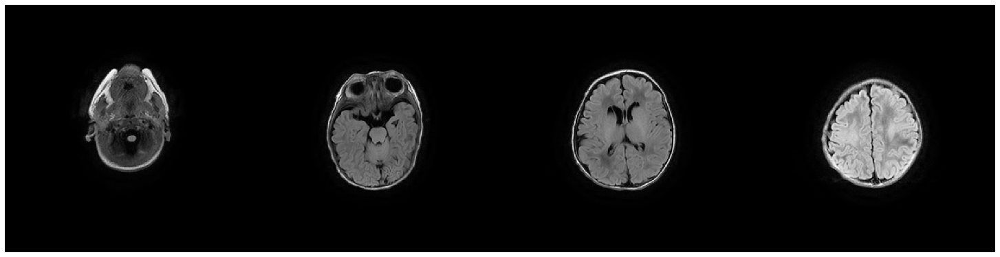

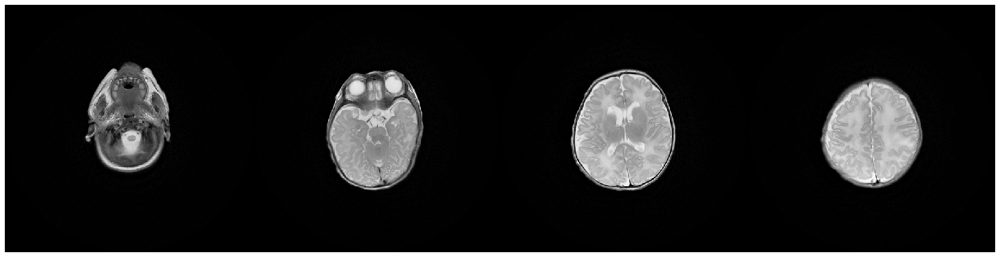

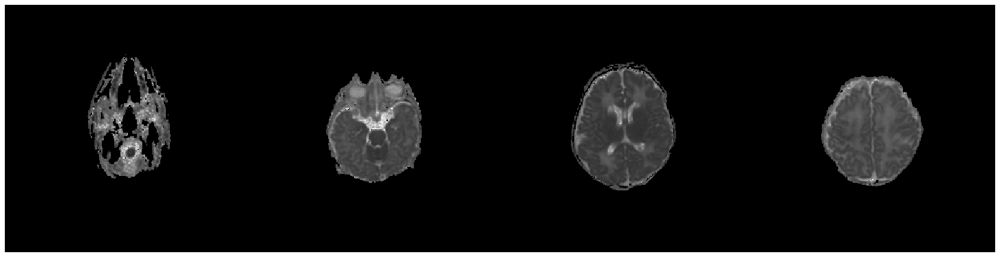

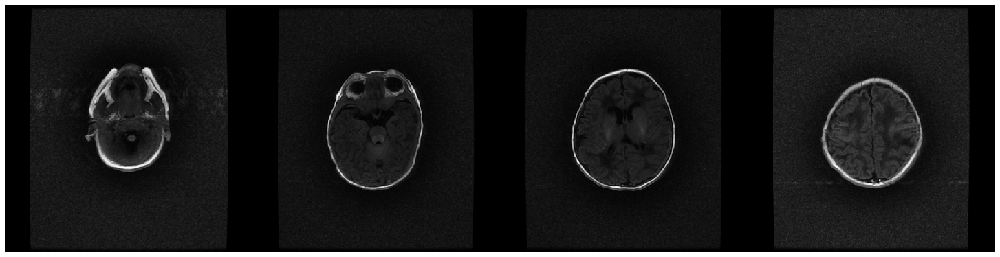

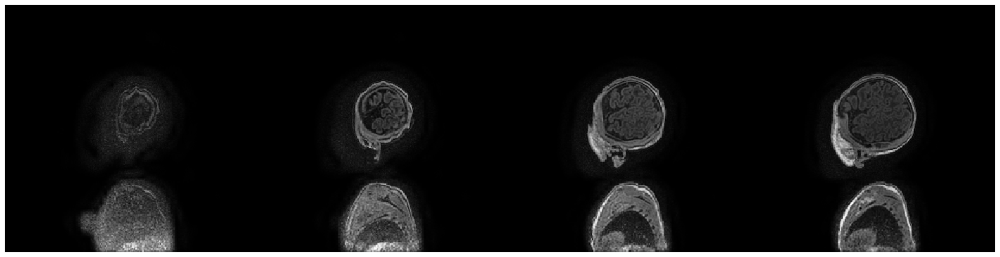

In [148]:
slices_num = [13, 10, 5, 0]
print(list(reversed(slices_num)))
ants.image_read(bids.loc[test_case1, ].t2f).plot(axis=2, slices=list(reversed(slices_num)), figsize=5)
ants.image_read(bids.loc[test_case1, ].t2).plot(axis=2, slices=list(reversed(slices_num)), figsize=5)
ants.image_read(bids.loc[test_case1, ].adc).plot(axis=2, slices=list(reversed(slices_num)), figsize=5)
ants.image_read(bids.loc[test_case1, ].t1).plot(axis=2, slices=list(reversed(slices_num)), figsize=5)
ants.image_read(bids.loc[test_case1, ].t1s).plot(axis=0, slices=list(reversed(slices_num)), figsize=5)

In [149]:
t2f = ants.image_read(bids.loc[test_case1, ].t2f)

## create stacked images

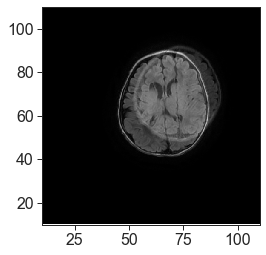

In [150]:
demo = np.zeros(t2f.shape[:2])

for i, sl in enumerate([13, 10, 5, 0]):
    if i == 0:
        mask = ants.slice_image(t2f, axis=2, idx=sl).get_mask()
        mask = np.rot90(mask2[:, :, sl])[:, ::-1], 60)
        demo[mask] = np.rot90(ants.slice_image(t2f, axis=2, idx=sl).numpy())[:, ::-1]
    else:
        mask = ants.slice_image(t2f, axis=2, idx=sl).get_mask()
        mask = np.roll(np.roll(np.rot90(mask2[:, :, sl])[:, ::-1], 60), -60, axis=0)
        demo[mask] = 
        
    plt.imshow(np.roll(np.roll(np.rot90(t2f[:, :, sl)[:, ::-1], 60), -60, axis=0),
               cmap=plt.cm.gray, extent=(10, 110, 10, 110), alpha=.9)